# MODULE 1: IMPORTS AND CONFIGURATION

In [4]:
# ==========================================
# MODULE 1: IMPORTS AND CONFIGURATION
# HEART DISEASE PREDICTION
# ==========================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Environment initialized successfully!")
print("Project: Heart Disease Prediction")

Environment initialized successfully!
Project: Heart Disease Prediction


# MODULE 2: DATASET LOADING AND INITIAL INSPECTION

In [5]:
# ==========================================
# MODULE 2: DATASET LOADING
# ==========================================

# Dataset paths
TRAIN_PATH = "/kaggle/input/competitions/playground-series-s6e2/train.csv"
TEST_PATH = "/kaggle/input/competitions/playground-series-s6e2/test.csv"

# Load datasets
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

# Dataset dimensions
print("TRAINING DATASET")
print("-" * 40)
print(f"Rows: {train.shape[0]}")
print(f"Columns: {train.shape[1]}")

print("\nTESTING DATASET")
print("-" * 40)
print(f"Rows: {test.shape[0]}")
print(f"Columns: {test.shape[1]}")

# Display first five records
print("\nFIRST FIVE RECORDS")
display(train.head())

# Dataset information
print("\nDATASET INFORMATION")
train.info()

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(train.describe(include="all").T)

# Missing values
print("\nMISSING VALUES")
display(train.isnull().sum())

# Column names
print("\nFEATURE NAMES")
print(train.columns.tolist())

TRAINING DATASET
----------------------------------------
Rows: 630000
Columns: 15

TESTING DATASET
----------------------------------------
Rows: 270000
Columns: 14

FIRST FIVE RECORDS


,id,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,0,58,1,4,152,239,0,0,158,1,3.6,2,2,7,Presence
1,1,52,1,1,125,325,0,2,171,0,0.0,1,0,3,Absence
2,2,56,0,2,160,188,0,2,151,0,0.0,1,0,3,Absence
3,3,44,0,3,134,229,0,2,150,0,1.0,2,0,3,Absence
4,4,58,1,4,140,234,0,2,125,1,3.8,2,3,3,Presence



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 630000 entries, 0 to 629999
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       630000 non-null  int64  
 1   Age                      630000 non-null  int64  
 2   Sex                      630000 non-null  int64  
 3   Chest pain type          630000 non-null  int64  
 4   BP                       630000 non-null  int64  
 5   Cholesterol              630000 non-null  int64  
 6   FBS over 120             630000 non-null  int64  
 7   EKG results              630000 non-null  int64  
 8   Max HR                   630000 non-null  int64  
 9   Exercise angina          630000 non-null  int64  
 10  ST depression            630000 non-null  float64
 11  Slope of ST              630000 non-null  int64  
 12  Number of vessels fluro  630000 non-null  int64  
 13  Thallium                 630000 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,630000.0,NaN,NaN,NaN,314999.5,181865.479132,0.0,157499.75,314999.5,472499.25,629999.0
Age,630000.0,NaN,NaN,NaN,54.136706,8.256301,29.0,48.0,54.0,60.0,77.0
Sex,630000.0,NaN,NaN,NaN,0.714735,0.451541,0.0,0.0,1.0,1.0,1.0
Chest pain type,630000.0,NaN,NaN,NaN,3.312752,0.851615,1.0,3.0,4.0,4.0,4.0
BP,630000.0,NaN,NaN,NaN,130.497433,14.975802,94.0,120.0,130.0,140.0,200.0
Cholesterol,630000.0,NaN,NaN,NaN,245.011814,33.681581,126.0,223.0,243.0,269.0,564.0
FBS over 120,630000.0,NaN,NaN,NaN,0.079987,0.271274,0.0,0.0,0.0,0.0,1.0
EKG results,630000.0,NaN,NaN,NaN,0.98166,0.998783,0.0,0.0,0.0,2.0,2.0
Max HR,630000.0,NaN,NaN,NaN,152.816763,19.112927,71.0,142.0,157.0,166.0,202.0
Exercise angina,630000.0,NaN,NaN,NaN,0.273725,0.44587,0.0,0.0,0.0,1.0,1.0



MISSING VALUES


id                         0
Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64


FEATURE NAMES
['id', 'Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']


# MODULE 3: DATA QUALITY CHECKS

In [6]:
# ==========================================
# 1. DUPLICATE CHECK
# ==========================================

print("Duplicate rows:", train.duplicated().sum())

print("Duplicate IDs:", train['id'].duplicated().sum())

# Check duplicate patient feature combinations
print(
    "Duplicate feature combinations:",
    train.drop(columns=['id', 'Heart Disease'])
         .duplicated()
         .sum()
)

Duplicate rows: 0
Duplicate IDs: 0
Duplicate feature combinations: 0


Heart Disease
Absence     347546
Presence    282454
Name: count, dtype: int64

Percentage Distribution:
Heart Disease
Absence     55.166032
Presence    44.833968
Name: proportion, dtype: float64


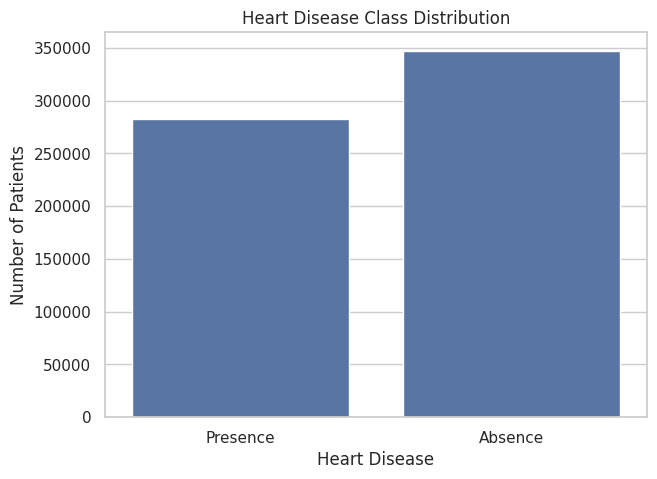

In [7]:
# ==========================================
# 2. TARGET DISTRIBUTION
# ==========================================

print(train['Heart Disease'].value_counts())

print("\nPercentage Distribution:")
print(
    train['Heart Disease']
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x='Heart Disease'
)

plt.title('Heart Disease Class Distribution')
plt.xlabel('Heart Disease')
plt.ylabel('Number of Patients')

plt.show()

In [8]:
# ==========================================
# 3. UNIQUE VALUES
# ==========================================

for column in train.columns:
    print(f"\n{column}")
    print(train[column].value_counts().sort_index())


id
id
0         1
1         1
2         1
3         1
4         1
         ..
629995    1
629996    1
629997    1
629998    1
629999    1
Name: count, Length: 630000, dtype: int64

Age
Age
29     1048
34     2623
35     3991
37     2481
38      931
39     5540
40     4554
41    24633
42    21958
43    16231
44    25476
45    14629
46    16246
47     6888
48    16282
49    10643
50    16659
51    37526
52    30572
53    15663
54    46826
55    11424
56    21149
57    32442
58    41714
59    31713
60    29437
61    13826
62    25872
63    13184
64    20109
65    17454
66    11771
67    17832
68     3849
69     4018
70     5950
71     4556
74      741
75        1
76      798
77      760
Name: count, dtype: int64

Sex
Sex
0    179717
1    450283
Name: count, dtype: int64

Chest pain type
Chest pain type
1     28602
2     74941
3    197278
4    329179
Name: count, dtype: int64

BP
BP
94     1711
95        1
96        1
99        3
100    5914
       ... 
178    1982
180    4269
184       1

In [9]:
# ==========================================
# 4. TRAIN-TEST COLUMN VALIDATION
# ==========================================

print("Training columns:")
print(train.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

print("\nMissing columns in test:")
print(set(train.columns) - set(test.columns))

Training columns:
['id', 'Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease']

Testing columns:
['id', 'Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium']

Missing columns in test:
{'Heart Disease'}


# MODULE 4: EXPLORATORY DATA ANALYSIS

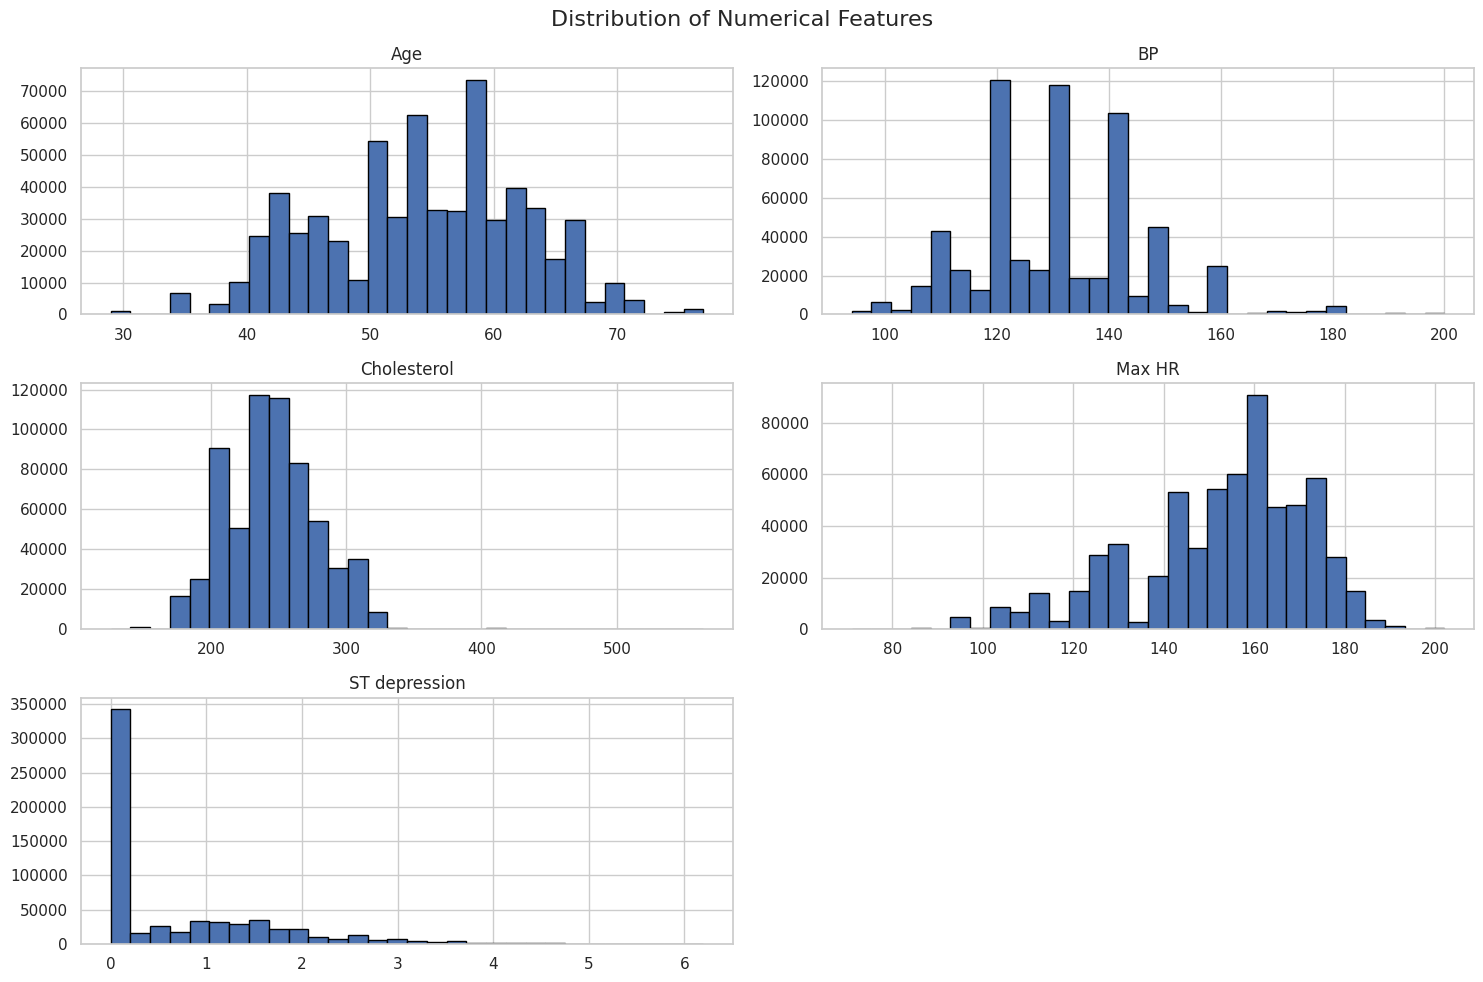

In [10]:
# Numerical feature distributions

numerical_features = [
    'Age',
    'BP',
    'Cholesterol',
    'Max HR',
    'ST depression'
]

train[numerical_features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

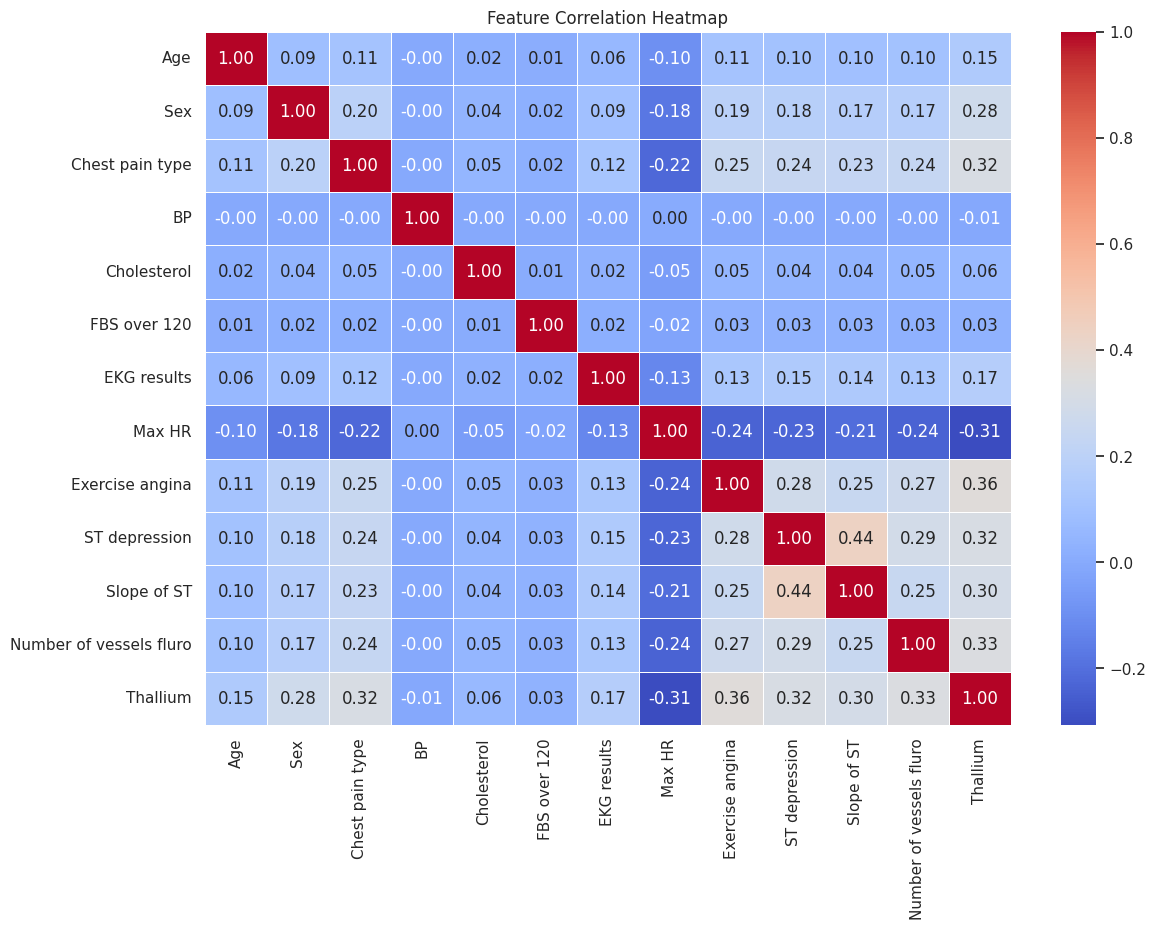

In [11]:
# Correlation analysis

plt.figure(figsize=(13, 9))

correlation = train.drop(
    columns=['id']
).corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap')
plt.show()

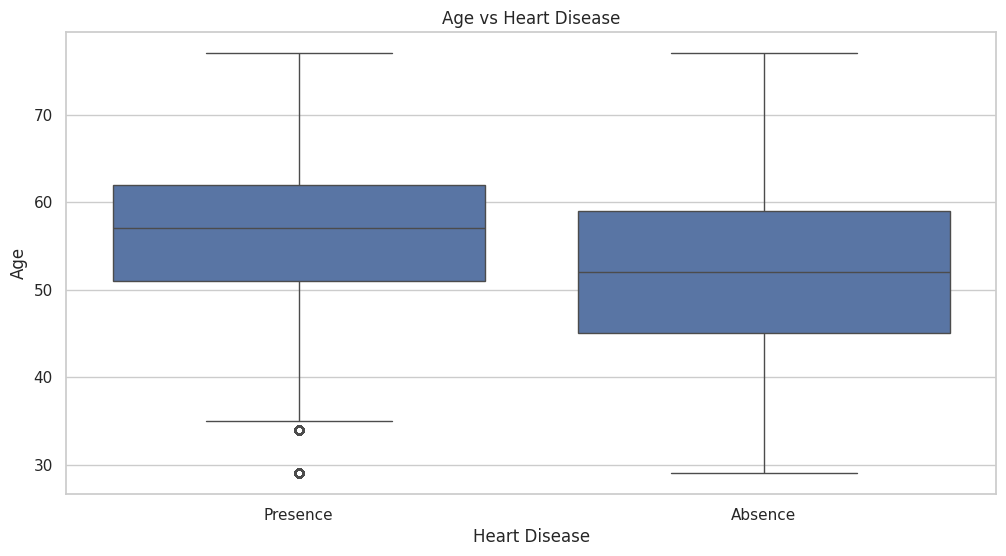

In [12]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=train,
    x='Heart Disease',
    y='Age'
)

plt.title('Age vs Heart Disease')
plt.show()

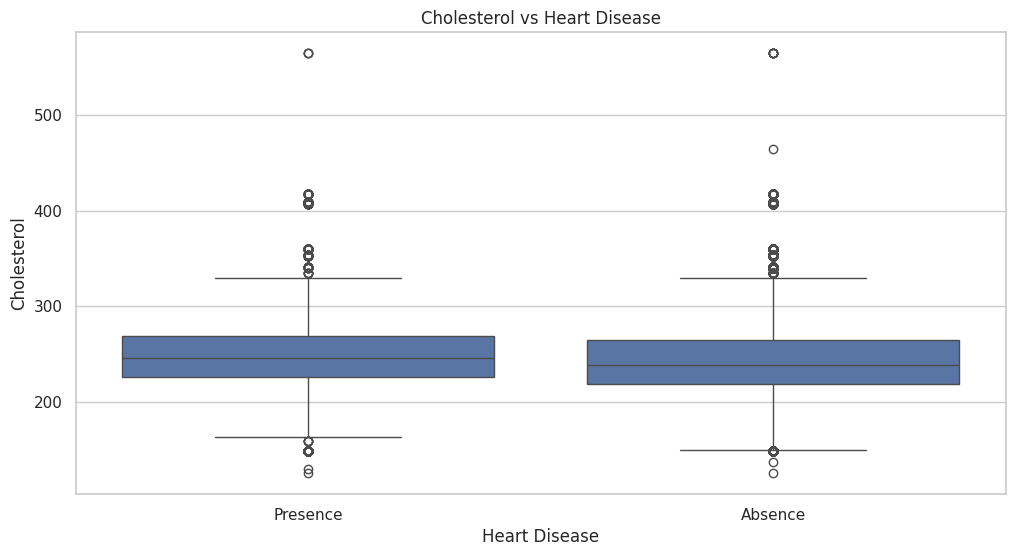

In [13]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=train,
    x='Heart Disease',
    y='Cholesterol'
)

plt.title('Cholesterol vs Heart Disease')
plt.show()

In [14]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo

# Download original UCI dataset
heart_disease = fetch_ucirepo(id=45)

# Extract features and target
uci_X = heart_disease.data.features
uci_y = heart_disease.data.targets

# Combine
uci = pd.concat([uci_X, uci_y], axis=1)

print("UCI Dataset Shape:", uci.shape)

display(uci.head())

print("\nDataset Information:")
uci.info()

print("\nMissing Values:")
print(uci.isnull().sum())

UCI Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        

# MODULE 5: UCI DATASET ANALYSIS

In [15]:
# ==========================================
# UCI TARGET ANALYSIS
# ==========================================

print("Original Target Distribution:")
print(uci['num'].value_counts().sort_index())

print("\nTarget Percentages:")
print(uci['num'].value_counts(normalize=True).sort_index() * 100)

# Binary target distribution
uci['Heart Disease'] = (uci['num'] > 0).astype(int)

print("\nBinary Target Distribution:")
print(uci['Heart Disease'].value_counts())

Original Target Distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Target Percentages:
num
0    54.125413
1    18.151815
2    11.881188
3    11.551155
4     4.290429
Name: proportion, dtype: float64

Binary Target Distribution:
Heart Disease
0    164
1    139
Name: count, dtype: int64


In [17]:
# ==========================================
# MISSING VALUE INVESTIGATION
# ==========================================

print("Missing Values:")
print(uci.isnull().sum())

print("\nRows with Missing Values:")

display(
    uci[uci.isnull().any(axis=1)]
)

Missing Values:
age              0
sex              0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalach          0
exang            0
oldpeak          0
slope            0
ca               4
thal             2
num              0
Heart Disease    0
dtype: int64

Rows with Missing Values:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,Heart Disease
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2,1
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0,0


In [18]:
# ==========================================
# UNIQUE VALUE INSPECTION
# ==========================================

categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

for column in categorical_features:
    print(f"\n{column}")
    print(uci[column].value_counts(dropna=False).sort_index())


sex
sex
0     97
1    206
Name: count, dtype: int64

cp
cp
1     23
2     50
3     86
4    144
Name: count, dtype: int64

fbs
fbs
0    258
1     45
Name: count, dtype: int64

restecg
restecg
0    151
1      4
2    148
Name: count, dtype: int64

exang
exang
0    204
1     99
Name: count, dtype: int64

slope
slope
1    142
2    140
3     21
Name: count, dtype: int64

ca
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal
thal
3.0    166
6.0     18
7.0    117
NaN      2
Name: count, dtype: int64


# MODULE 6: DATA CLEANING AND HARMONIZATION


In [19]:
# ==========================================
# STANDARDIZE UCI COLUMN NAMES
# ==========================================

column_mapping = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'Chest pain type',
    'trestbps': 'BP',
    'chol': 'Cholesterol',
    'fbs': 'FBS over 120',
    'restecg': 'EKG results',
    'thalach': 'Max HR',
    'exang': 'Exercise angina',
    'oldpeak': 'ST depression',
    'slope': 'Slope of ST',
    'ca': 'Number of vessels fluro',
    'thal': 'Thallium'
}

uci_clean = uci.rename(columns=column_mapping).copy()

print("Standardized UCI columns:")
print(uci_clean.columns.tolist())

Standardized UCI columns:
['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120', 'EKG results', 'Max HR', 'Exercise angina', 'ST depression', 'Slope of ST', 'Number of vessels fluro', 'Thallium', 'num', 'Heart Disease']


In [20]:
# ==========================================
# TARGET STANDARDIZATION
# ==========================================

# UCI target: 0 = Absence, 1-4 = Presence
uci_clean['Heart Disease'] = (
    uci_clean['num'] > 0
).astype(int)

# Playground target
playground_clean = train.copy()

playground_clean['Heart Disease'] = (
    playground_clean['Heart Disease']
    .map({'Absence': 0, 'Presence': 1})
)

print("UCI Target:")
print(uci_clean['Heart Disease'].value_counts())

print("\nPlayground Target:")
print(playground_clean['Heart Disease'].value_counts())

UCI Target:
Heart Disease
0    164
1    139
Name: count, dtype: int64

Playground Target:
Heart Disease
0    347546
1    282454
Name: count, dtype: int64


In [21]:
# ==========================================
# REMOVE UNNECESSARY COLUMNS
# ==========================================

uci_clean.drop(
    columns=['num', 'id'],
    errors='ignore',
    inplace=True
)

playground_clean.drop(
    columns=['id'],
    inplace=True
)

print("UCI Shape:", uci_clean.shape)
print("Playground Shape:", playground_clean.shape)

UCI Shape: (303, 14)
Playground Shape: (630000, 14)


In [22]:
# ==========================================
# FEATURE COMPATIBILITY
# ==========================================

uci_features = set(uci_clean.columns) - {'Heart Disease'}

playground_features = set(playground_clean.columns) - {'Heart Disease'}

print("Features present in both datasets:")
print(sorted(uci_features.intersection(playground_features)))

print("\nFeatures missing from UCI:")
print(playground_features - uci_features)

print("\nFeatures missing from Playground:")
print(uci_features - playground_features)

Features present in both datasets:
['Age', 'BP', 'Chest pain type', 'Cholesterol', 'EKG results', 'Exercise angina', 'FBS over 120', 'Max HR', 'Number of vessels fluro', 'ST depression', 'Sex', 'Slope of ST', 'Thallium']

Features missing from UCI:
set()

Features missing from Playground:
set()


# MODULE 7: COMPARATIVE DATA ANALYSIS

In [24]:
# ==========================================
# FEATURE CATEGORIZATION
# ==========================================

numerical_features = [
    'Age',
    'BP',
    'Cholesterol',
    'Max HR',
    'ST depression'
]

categorical_features = [
    'Sex',
    'Chest pain type',
    'FBS over 120',
    'EKG results',
    'Exercise angina',
    'Slope of ST',
    'Number of vessels fluro',
    'Thallium'
]

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 5
Categorical Features: 8


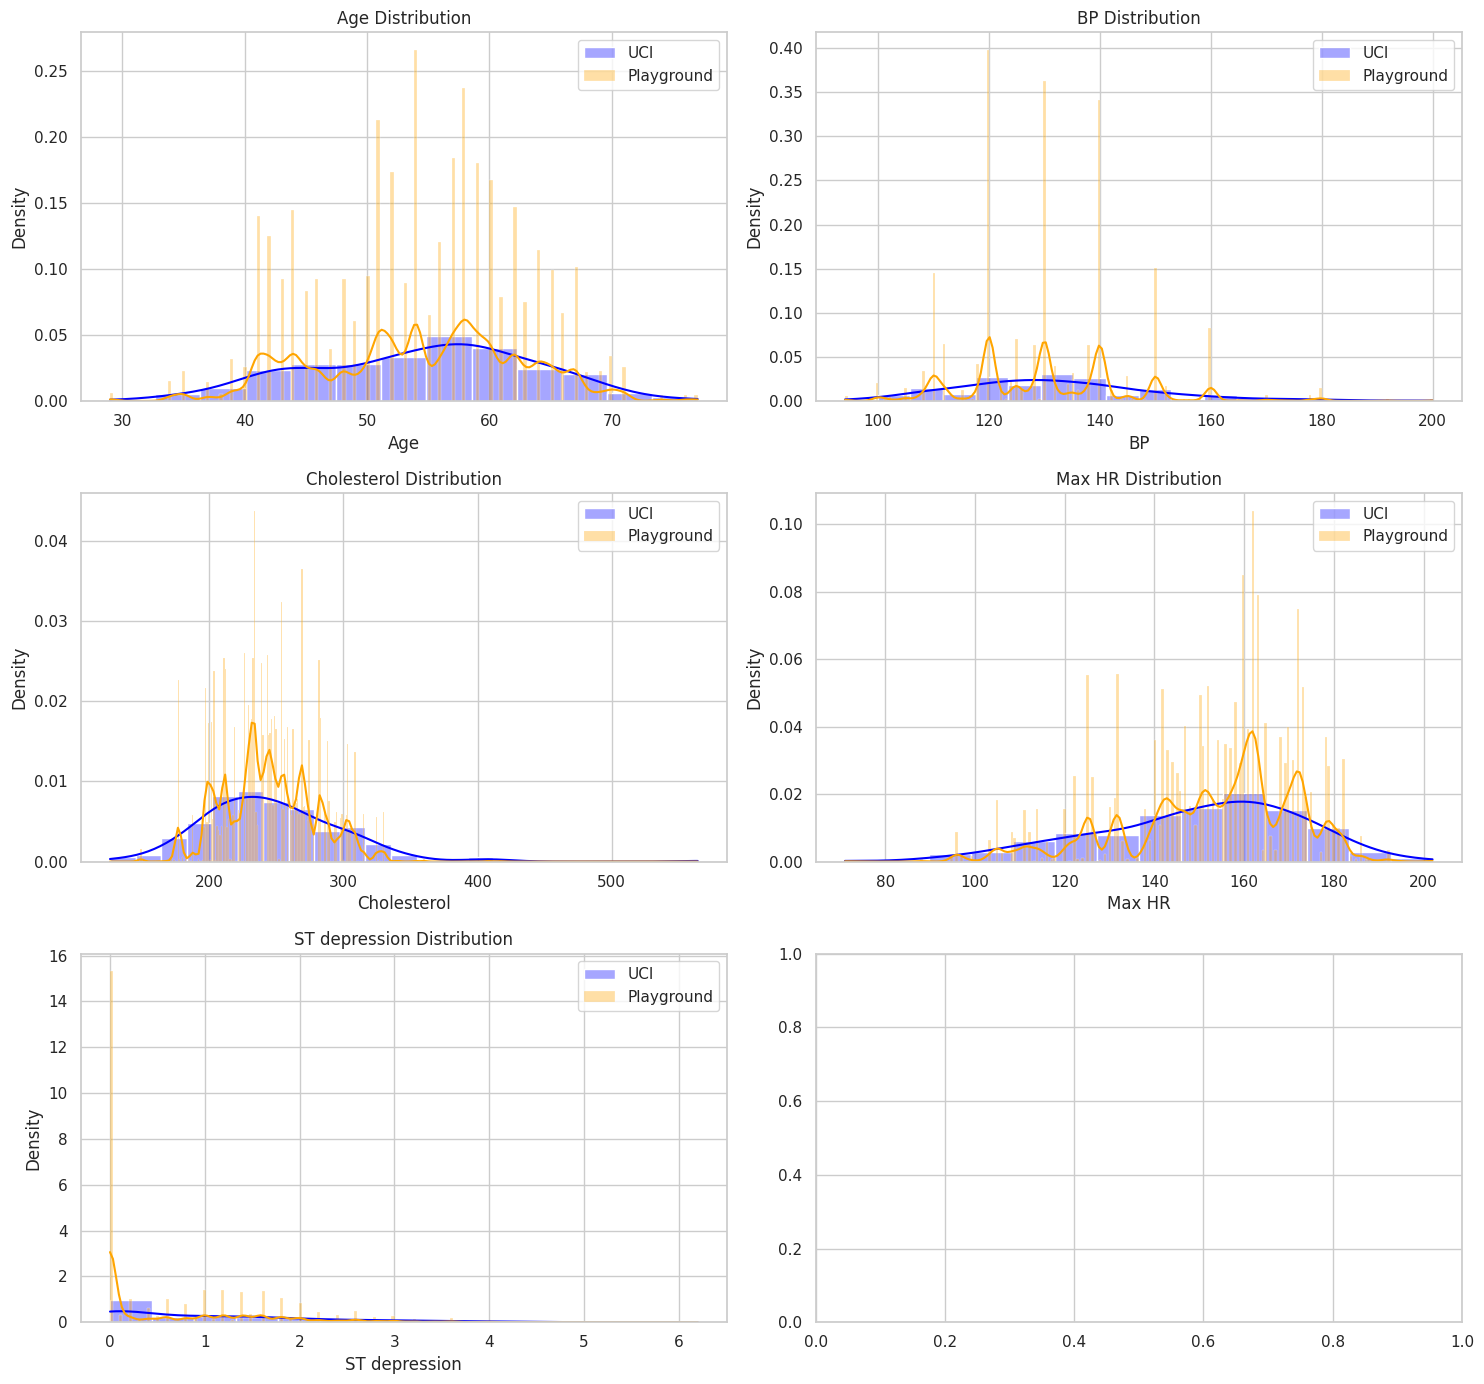

In [25]:
# ==========================================
# NUMERICAL DISTRIBUTION COMPARISON
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for feature, ax in zip(numerical_features, axes.flatten()):

    sns.histplot(
        uci_clean[feature],
        label='UCI',
        color='blue',
        stat='density',
        kde=True,
        alpha=0.35,
        ax=ax
    )

    sns.histplot(
        playground_clean[feature],
        label='Playground',
        color='orange',
        stat='density',
        kde=True,
        alpha=0.35,
        ax=ax
    )

    ax.set_title(f'{feature} Distribution')
    ax.legend()

plt.tight_layout()
plt.show()

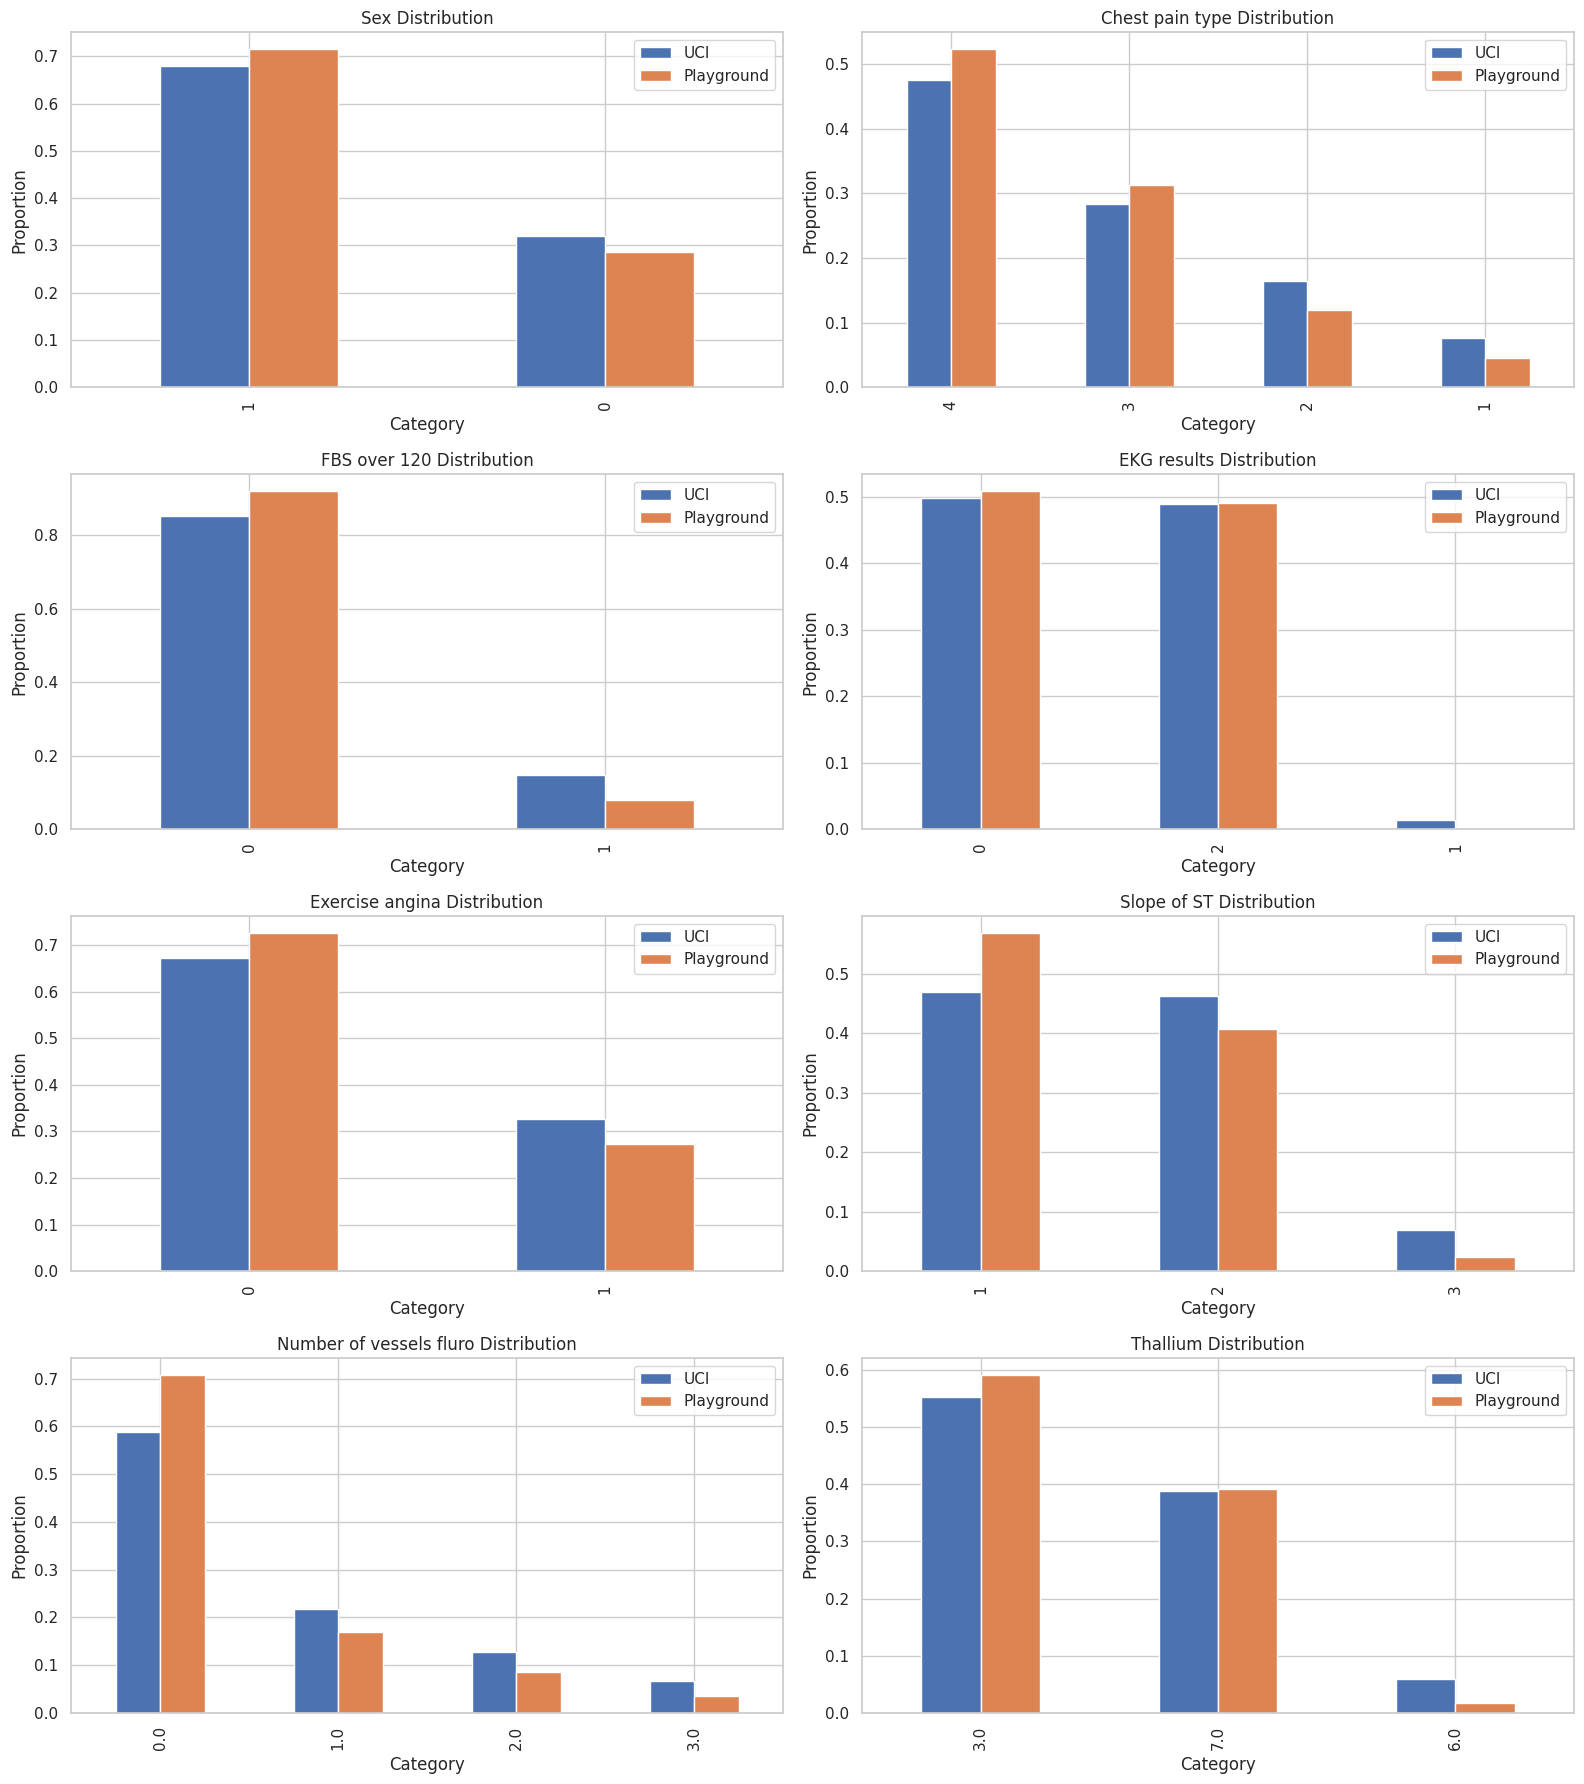

In [26]:
# ==========================================
# CATEGORICAL DISTRIBUTION COMPARISON
# ==========================================

fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for feature, ax in zip(categorical_features, axes.flatten()):

    uci_dist = uci_clean[feature].value_counts(
        normalize=True
    )

    playground_dist = playground_clean[feature].value_counts(
        normalize=True
    )

    comparison = pd.DataFrame({
        'UCI': uci_dist,
        'Playground': playground_dist
    }).fillna(0)

    comparison.plot(
        kind='bar',
        ax=ax
    )

    ax.set_title(f'{feature} Distribution')
    ax.set_ylabel('Proportion')
    ax.set_xlabel('Category')
    ax.legend()

plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# STATISTICAL COMPARISON
# ==========================================

uci_summary = uci_clean[numerical_features].describe().T

playground_summary = playground_clean[numerical_features].describe().T

comparison = pd.concat(
    [
        uci_summary.add_suffix('_UCI'),
        playground_summary.add_suffix('_Playground')
    ],
    axis=1
)

display(comparison.round(2))

,count_UCI,mean_UCI,std_UCI,min_UCI,25%_UCI,50%_UCI,75%_UCI,max_UCI,count_Playground,mean_Playground,std_Playground,min_Playground,25%_Playground,50%_Playground,75%_Playground,max_Playground
Age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0,630000.0,54.14,8.26,29.0,48.0,54.0,60.0,77.0
BP,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0,630000.0,130.50,14.98,94.0,120.0,130.0,140.0,200.0
Cholesterol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0,630000.0,245.01,33.68,126.0,223.0,243.0,269.0,564.0
Max HR,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0,630000.0,152.82,19.11,71.0,142.0,157.0,166.0,202.0
ST depression,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2,630000.0,0.72,0.95,0.0,0.0,0.1,1.4,6.2


# MODULE 8: DATA QUALITY AND DOMAIN VALIDATION

In [28]:
# ==========================================
# FEATURE RANGE COMPARISON
# ==========================================

for feature in numerical_features:

    print(f"\n{'='*45}")
    print(f"FEATURE: {feature}")
    print('='*45)

    print("UCI:")
    print(uci_clean[feature].describe())

    print("\nPlayground:")
    print(playground_clean[feature].describe())


FEATURE: Age
UCI:
count    303.000000
mean      54.438944
std        9.038662
min       29.000000
25%       48.000000
50%       56.000000
75%       61.000000
max       77.000000
Name: Age, dtype: float64

Playground:
count    630000.000000
mean         54.136706
std           8.256301
min          29.000000
25%          48.000000
50%          54.000000
75%          60.000000
max          77.000000
Name: Age, dtype: float64

FEATURE: BP
UCI:
count    303.000000
mean     131.689769
std       17.599748
min       94.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: BP, dtype: float64

Playground:
count    630000.000000
mean        130.497433
std          14.975802
min          94.000000
25%         120.000000
50%         130.000000
75%         140.000000
max         200.000000
Name: BP, dtype: float64

FEATURE: Cholesterol
UCI:
count    303.000000
mean     246.693069
std       51.776918
min      126.000000
25%      211.000000
50%      241.000000


In [29]:
# ==========================================
# CATEGORICAL VALUE VALIDATION
# ==========================================

for feature in categorical_features:

    uci_values = set(
        uci_clean[feature].dropna().unique()
    )

    playground_values = set(
        playground_clean[feature].dropna().unique()
    )

    print(f"\nFeature: {feature}")
    print("UCI categories:", sorted(uci_values))
    print("Playground categories:", sorted(playground_values))

    print(
        "Categories only in UCI:",
        uci_values - playground_values
    )

    print(
        "Categories only in Playground:",
        playground_values - uci_values
    )


Feature: Sex
UCI categories: [np.int64(0), np.int64(1)]
Playground categories: [np.int64(0), np.int64(1)]
Categories only in UCI: set()
Categories only in Playground: set()

Feature: Chest pain type
UCI categories: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Playground categories: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Categories only in UCI: set()
Categories only in Playground: set()

Feature: FBS over 120
UCI categories: [np.int64(0), np.int64(1)]
Playground categories: [np.int64(0), np.int64(1)]
Categories only in UCI: set()
Categories only in Playground: set()

Feature: EKG results
UCI categories: [np.int64(0), np.int64(1), np.int64(2)]
Playground categories: [np.int64(0), np.int64(1), np.int64(2)]
Categories only in UCI: set()
Categories only in Playground: set()

Feature: Exercise angina
UCI categories: [np.int64(0), np.int64(1)]
Playground categories: [np.int64(0), np.int64(1)]
Categories only in UCI: set()
Categories only in Playground: set()

Feature: S

In [30]:
# ==========================================
# FINAL MISSING VALUE REPORT
# ==========================================

print("UCI Missing Values:")
display(uci_clean.isnull().sum())

print("\nPlayground Missing Values:")
display(playground_clean.isnull().sum())

UCI Missing Values:


Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    4
Thallium                   2
Heart Disease              0
dtype: int64


Playground Missing Values:


Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

# MODULE 9: DATA PREPROCESSING

In [31]:
# ==========================================
# SEPARATE FEATURES AND TARGET
# ==========================================

X_playground = playground_clean.drop(
    columns=['Heart Disease']
)

y_playground = playground_clean['Heart Disease']

X_uci = uci_clean.drop(
    columns=['Heart Disease']
)

y_uci = uci_clean['Heart Disease']

print("Playground X:", X_playground.shape)
print("Playground y:", y_playground.shape)

print("\nUCI X:", X_uci.shape)
print("UCI y:", y_uci.shape)

Playground X: (630000, 13)
Playground y: (630000,)

UCI X: (303, 13)
UCI y: (303,)


In [32]:
# ==========================================
# FEATURE CONFIGURATION
# ==========================================

numerical_features = [
    'Age',
    'BP',
    'Cholesterol',
    'Max HR',
    'ST depression'
]

categorical_features = [
    'Sex',
    'Chest pain type',
    'FBS over 120',
    'EKG results',
    'Exercise angina',
    'Slope of ST',
    'Number of vessels fluro',
    'Thallium'
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 5
Categorical features: 8


In [33]:
# ==========================================
# PREPROCESSING PIPELINE
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


# MODULE 10: MODEL DEVELOPMENT

In [34]:
# ==========================================
# TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_playground,
    y_playground,
    test_size=0.20,
    random_state=42,
    stratify=y_playground
)

print("Training samples:", X_train.shape)
print("Validation samples:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Training samples: (504000, 13)
Validation samples: (126000, 13)

Training target distribution:
Heart Disease
0    0.551661
1    0.448339
Name: proportion, dtype: float64

Validation target distribution:
Heart Disease
0    0.551659
1    0.448341
Name: proportion, dtype: float64


In [35]:
# ==========================================
# LOGISTIC REGRESSION
# ==========================================

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [36]:
# ==========================================
# MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predictions
y_pred = logistic_model.predict(X_val)

# Probability predictions
y_prob = logistic_model.predict_proba(X_val)[:, 1]

# Evaluation metrics
print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("F1 Score:", f1_score(y_val, y_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.8870555555555556
Precision: 0.8838468245894492
Recall: 0.8612699368040927
F1 Score: 0.8724123400783582
ROC-AUC: 0.9537010543765575

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90     69509
           1       0.88      0.86      0.87     56491

    accuracy                           0.89    126000
   macro avg       0.89      0.88      0.89    126000
weighted avg       0.89      0.89      0.89    126000



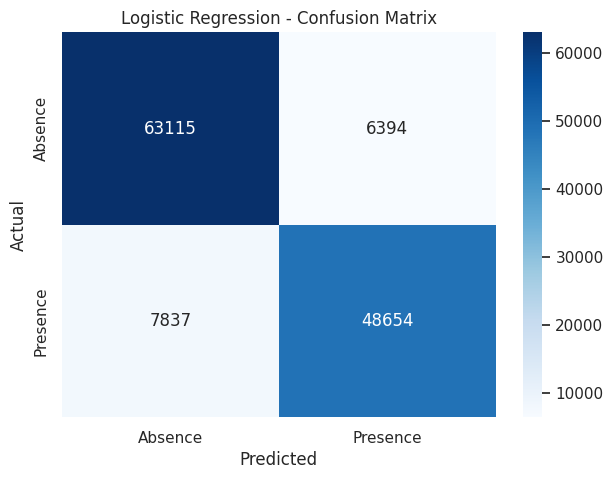

In [37]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Absence', 'Presence'],
    yticklabels=['Absence', 'Presence']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

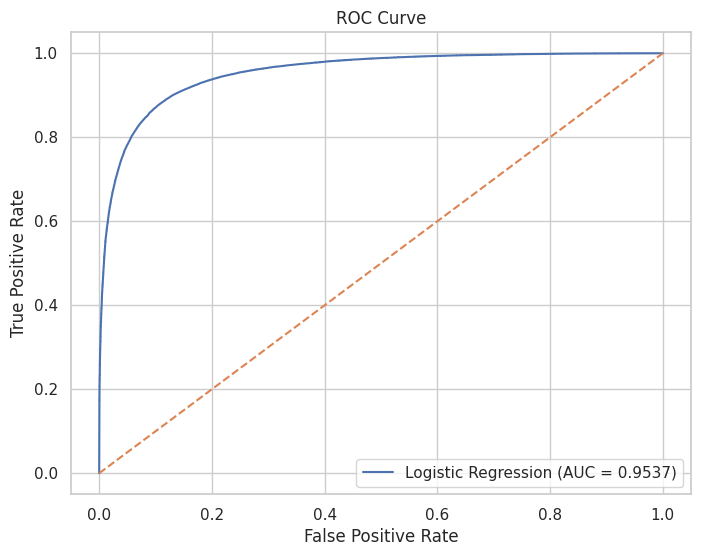

In [38]:
# ==========================================
# ROC CURVE
# ==========================================

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_val, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve')
plt.legend()

plt.show()

# Experiment 1: Logistic Regression
1. Model performance
Your results:
Evaluation Metric	Score
Accuracy	88.71%
Precision	88.38%
Recall (Sensitivity)	86.13%
F1-score	87.24%
ROC-AUC	95.37%


My interpretation
Accuracy – 88.71%

The model correctly classified approximately 89 out of every 100 validation records.

Precision – 88.38%

Among records predicted as having heart disease, approximately 88% actually belong to the positive class.

Recall – 86.13%

The model identified approximately 86% of the actual positive records.

ROC-AUC – 95.37%

This indicates excellent discrimination between the two classes within this synthetic validation dataset.
2. Confusion matrix analysis
Your confusion matrix:
	Predicted Absence	Predicted Presence
Actual Absence	63,115	6,394
Actual Presence	7,837	48,654


Additional metrics:
- True Negatives: 63,115
- False Positives: 6,394
- False Negatives: 7,837
- True Positives: 48,654
- Specificity: 90.80%
For a healthcare-related application, false negatives deserve particular attention.

Remember, these are results on synthetic competition data, not evidence of clinical diagnostic performance.

# EXPERIMENT 2: RANDOM FOREST CLASSIFIER

In [39]:
# ==========================================
# RANDOM FOREST CLASSIFIER
# ==========================================

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),

    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [40]:
# ==========================================
# MODEL TRAINING
# ==========================================

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [41]:
# ==========================================
# RANDOM FOREST EVALUATION
# ==========================================

rf_pred = rf_model.predict(X_val)

rf_prob = rf_model.predict_proba(X_val)[:, 1]

print("RANDOM FOREST RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, rf_pred))

print("Precision:", precision_score(y_val, rf_pred))

print("Recall:", recall_score(y_val, rf_pred))

print("F1 Score:", f1_score(y_val, rf_pred))

print("ROC-AUC:", roc_auc_score(y_val, rf_prob))

print("\nClassification Report:")
print(classification_report(y_val, rf_pred))

RANDOM FOREST RESULTS
Accuracy: 0.8846507936507937
Precision: 0.876559386835634
Recall: 0.8644562850719584
F1 Score: 0.8704657670986257
ROC-AUC: 0.9507243447525326

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.90     69509
           1       0.88      0.86      0.87     56491

    accuracy                           0.88    126000
   macro avg       0.88      0.88      0.88    126000
weighted avg       0.88      0.88      0.88    126000



In [42]:
# ==========================================
# MODEL COMPARISON
# ==========================================

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],

    'Accuracy': [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred)
    ],

    'Precision': [
        precision_score(y_val, y_pred),
        precision_score(y_val, rf_pred)
    ],

    'Recall': [
        recall_score(y_val, y_pred),
        recall_score(y_val, rf_pred)
    ],

    'F1 Score': [
        f1_score(y_val, y_pred),
        f1_score(y_val, rf_pred)
    ],

    'ROC-AUC': [
        roc_auc_score(y_val, y_prob),
        roc_auc_score(y_val, rf_prob)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8871,0.8838,0.8613,0.8724,0.9537
1,Random Forest,0.8847,0.8766,0.8645,0.8705,0.9507


# MODULE 11: XGBOOST CLASSIFIER

In [44]:
!pip install -q xgboost

from xgboost import XGBClassifier
import time

# Experiment 3 — XGBoost
This is where things get interesting.

XGBoost uses boosting rather than bagging like Random Forest.

We'll configure it to display:
- Current boosting iteration.
- Training progress.
- Validation performance.
- Total training time.

In [45]:
# ==========================================
# EXPERIMENT 3: XGBOOST
# ==========================================

xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),

    ('classifier', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1,
        tree_method='hist'
    ))
])

print("XGBoost pipeline created!")

XGBoost pipeline created!


In [46]:
# ==========================================
# XGBOOST TRAINING
# ==========================================

start_time = time.perf_counter()

xgb_model.fit(X_train, y_train)

end_time = time.perf_counter()

training_time = end_time - start_time

print("XGBoost training completed!")
print(f"Training time: {training_time:.2f} seconds")
print(f"Training time: {training_time/60:.2f} minutes")

XGBoost training completed!
Training time: 9.57 seconds
Training time: 0.16 minutes


In [47]:
# ==========================================
# XGBOOST EVALUATION
# ==========================================

xgb_pred = xgb_model.predict(X_val)

xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

print("XGBOOST RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, xgb_pred))
print("Precision:", precision_score(y_val, xgb_pred))
print("Recall:", recall_score(y_val, xgb_pred))
print("F1 Score:", f1_score(y_val, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_val, xgb_prob))

print("\nClassification Report:")
print(classification_report(y_val, xgb_pred))

XGBOOST RESULTS
Accuracy: 0.8894761904761905
Precision: 0.8834477415635191
Recall: 0.8679966720362535
F1 Score: 0.8756540528956909
ROC-AUC: 0.9558797306563303

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90     69509
           1       0.88      0.87      0.88     56491

    accuracy                           0.89    126000
   macro avg       0.89      0.89      0.89    126000
weighted avg       0.89      0.89      0.89    126000



In [48]:
# ==========================================
# UPDATED MODEL COMPARISON
# ==========================================

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, xgb_pred)
    ],

    'Precision': [
        precision_score(y_val, y_pred),
        precision_score(y_val, rf_pred),
        precision_score(y_val, xgb_pred)
    ],

    'Recall': [
        recall_score(y_val, y_pred),
        recall_score(y_val, rf_pred),
        recall_score(y_val, xgb_pred)
    ],

    'F1 Score': [
        f1_score(y_val, y_pred),
        f1_score(y_val, rf_pred),
        f1_score(y_val, xgb_pred)
    ],

    'ROC-AUC': [
        roc_auc_score(y_val, y_prob),
        roc_auc_score(y_val, rf_prob),
        roc_auc_score(y_val, xgb_prob)
    ]
})

display(results.sort_values(
    by='ROC-AUC',
    ascending=False
).round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.8895,0.8834,0.8680,0.8757,0.9559
0,Logistic Regression,0.8871,0.8838,0.8613,0.8724,0.9537
1,Random Forest,0.8847,0.8766,0.8645,0.8705,0.9507


In [49]:
# Prepare UCI features and target

X_uci = uci_clean.drop(columns=['Heart Disease'])
y_uci = uci_clean['Heart Disease']

print("UCI Dataset Shape:", X_uci.shape)
print("\nTarget Distribution:")
print(y_uci.value_counts())

UCI Dataset Shape: (303, 13)

Target Distribution:
Heart Disease
0    164
1    139
Name: count, dtype: int64


# Experiment 4 — Synthetic data → Original UCI data

In [50]:
# ==========================================
# CROSS-DATASET VALIDATION
# Playground-trained XGBoost -> UCI dataset
# ==========================================

uci_pred = xgb_model.predict(X_uci)
uci_prob = xgb_model.predict_proba(X_uci)[:, 1]

print("CROSS-DATASET RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_uci, uci_pred))
print("Precision:", precision_score(y_uci, uci_pred))
print("Recall:", recall_score(y_uci, uci_pred))
print("F1 Score:", f1_score(y_uci, uci_pred))
print("ROC-AUC:", roc_auc_score(y_uci, uci_prob))

print("\nClassification Report:")
print(classification_report(y_uci, uci_pred))

CROSS-DATASET RESULTS
Accuracy: 0.8184818481848185
Precision: 0.7916666666666666
Recall: 0.8201438848920863
F1 Score: 0.8056537102473498
ROC-AUC: 0.9172661870503598

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83       164
           1       0.79      0.82      0.81       139

    accuracy                           0.82       303
   macro avg       0.82      0.82      0.82       303
weighted avg       0.82      0.82      0.82       303



In [51]:
# ==========================================
# UCI TRAIN-TEST SPLIT
# ==========================================

X_uci_train, X_uci_test, y_uci_train, y_uci_test = train_test_split(
    X_uci,
    y_uci,
    test_size=0.20,
    random_state=42,
    stratify=y_uci
)

print("UCI Training Shape:", X_uci_train.shape)
print("UCI Testing Shape:", X_uci_test.shape)

UCI Training Shape: (242, 13)
UCI Testing Shape: (61, 13)


In [52]:
# ==========================================
# REVERSE CROSS-DATASET EXPERIMENT
# Train: UCI | Test: UCI + Playground
# ==========================================

import time

uci_xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1,
        tree_method='hist'
    ))
])

start_time = time.perf_counter()

uci_xgb_model.fit(X_uci_train, y_uci_train)

training_time = time.perf_counter() - start_time

print("UCI XGBoost Training Completed!")
print(f"Training time: {training_time:.2f} seconds")

UCI XGBoost Training Completed!
Training time: 0.13 seconds


In [53]:
# ==========================================
# UCI MODEL - INTERNAL TEST EVALUATION
# ==========================================

uci_test_pred = uci_xgb_model.predict(X_uci_test)
uci_test_prob = uci_xgb_model.predict_proba(X_uci_test)[:, 1]

print("UCI XGBOOST TEST RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_uci_test, uci_test_pred))
print("Precision:", precision_score(y_uci_test, uci_test_pred))
print("Recall:", recall_score(y_uci_test, uci_test_pred))
print("F1 Score:", f1_score(y_uci_test, uci_test_pred))
print("ROC-AUC:", roc_auc_score(y_uci_test, uci_test_prob))

print("\nClassification Report:")
print(classification_report(y_uci_test, uci_test_pred))

UCI XGBOOST TEST RESULTS
Accuracy: 0.8852459016393442
Precision: 0.8181818181818182
Recall: 0.9642857142857143
F1 Score: 0.8852459016393442
ROC-AUC: 0.9426406926406926

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.82      0.89        33
           1       0.82      0.96      0.89        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.89      0.89        61



In [54]:
# ==========================================
# UCI TRAINED MODEL -> PLAYGROUND VALIDATION
# ==========================================

playground_pred = uci_xgb_model.predict(X_val)
playground_prob = uci_xgb_model.predict_proba(X_val)[:, 1]

print("UCI TO PLAYGROUND RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, playground_pred))
print("Precision:", precision_score(y_val, playground_pred))
print("Recall:", recall_score(y_val, playground_pred))
print("F1 Score:", f1_score(y_val, playground_pred))
print("ROC-AUC:", roc_auc_score(y_val, playground_prob))

print("\nClassification Report:")
print(classification_report(y_val, playground_pred))

UCI TO PLAYGROUND RESULTS
Accuracy: 0.8432380952380952
Precision: 0.8419426295117366
Recall: 0.8006585119753589
F1 Score: 0.8207817660508837
ROC-AUC: 0.9190836329613118

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86     69509
           1       0.84      0.80      0.82     56491

    accuracy                           0.84    126000
   macro avg       0.84      0.84      0.84    126000
weighted avg       0.84      0.84      0.84    126000



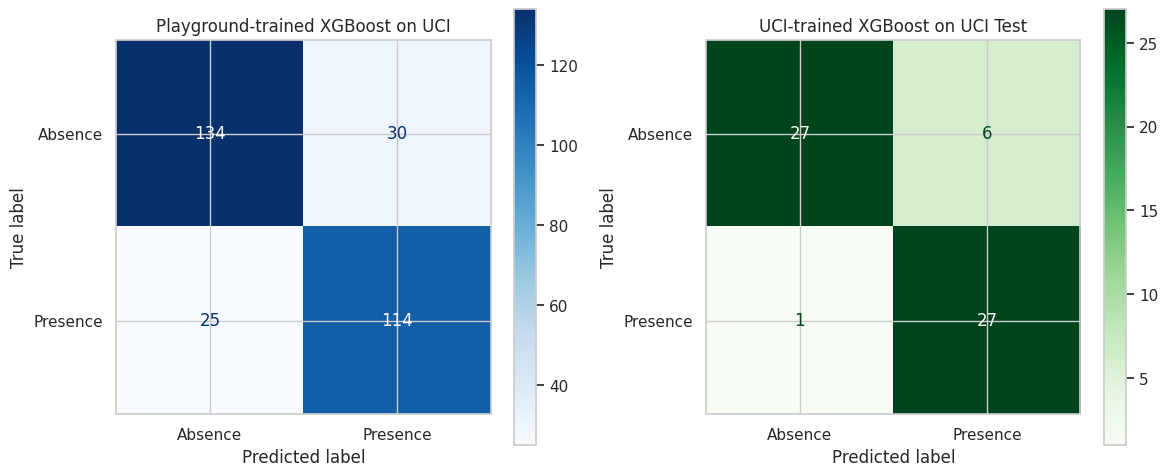

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_uci, uci_pred,
    display_labels=["Absence", "Presence"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Playground-trained XGBoost on UCI")

ConfusionMatrixDisplay.from_predictions(
    y_uci_test, uci_test_pred,
    display_labels=["Absence", "Presence"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("UCI-trained XGBoost on UCI Test")

plt.tight_layout()
plt.show()

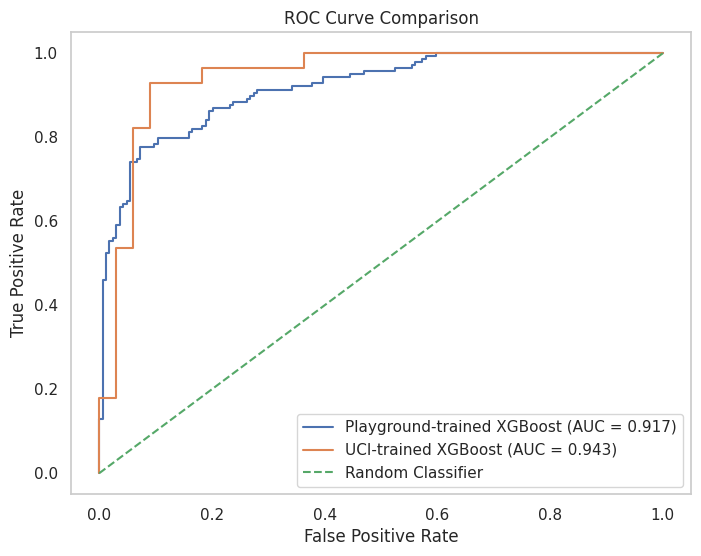

In [56]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curves
fpr_playground, tpr_playground, _ = roc_curve(y_uci, uci_prob)
fpr_uci, tpr_uci, _ = roc_curve(y_uci_test, uci_test_prob)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_playground,
    tpr_playground,
    label=f"Playground-trained XGBoost (AUC = {auc(fpr_playground, tpr_playground):.3f})"
)

plt.plot(
    fpr_uci,
    tpr_uci,
    label=f"UCI-trained XGBoost (AUC = {auc(fpr_uci, tpr_uci):.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

                             Feature  Importance
25                 cat__Thallium_3.0    0.369728
27                 cat__Thallium_7.0    0.242936
10          cat__Chest pain type_4.0    0.160250
21  cat__Number of vessels fluro_0.0    0.051450
18              cat__Slope of ST_1.0    0.032944
16          cat__Exercise angina_0.0    0.025377
17          cat__Exercise angina_1.0    0.020971
3                        num__Max HR    0.012796
5                       cat__Sex_0.0    0.012593
6                       cat__Sex_1.0    0.012449
4                 num__ST depression    0.009761
19              cat__Slope of ST_2.0    0.008612
9           cat__Chest pain type_3.0    0.007169
15              cat__EKG results_2.0    0.006587
22  cat__Number of vessels fluro_1.0    0.006100
0                           num__Age    0.003546
13              cat__EKG results_0.0    0.003136
23  cat__Number of vessels fluro_2.0    0.002876
7           cat__Chest pain type_1.0    0.002562
8           cat__Che

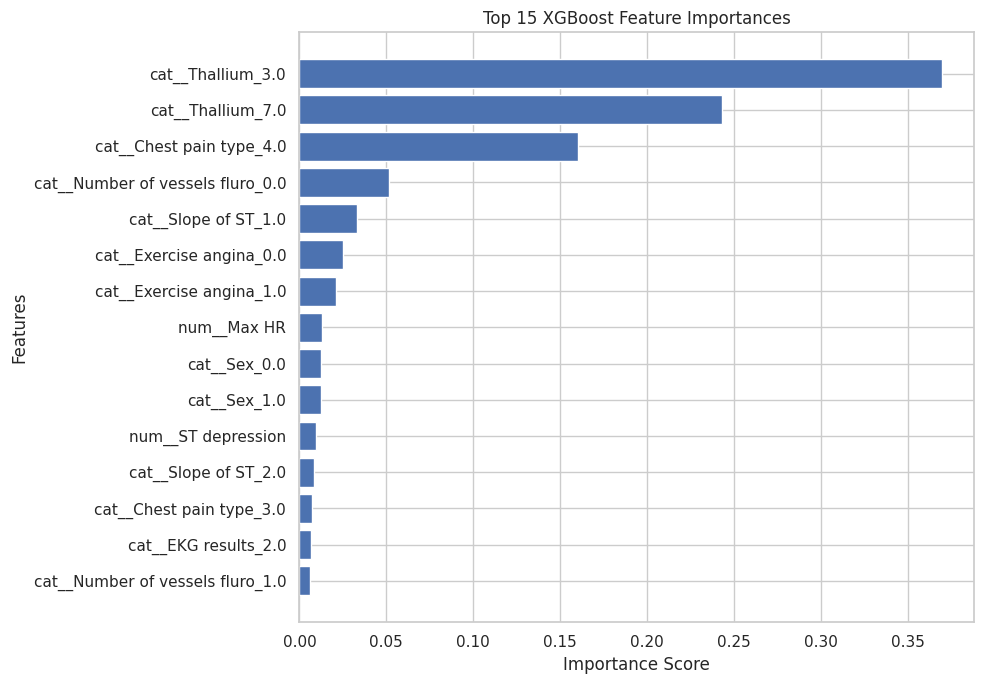

In [57]:
# ==========================================
# XGBOOST FEATURE IMPORTANCE
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# Get trained XGBoost classifier
xgb_classifier = xgb_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = xgb_model.named_steps['preprocessor'].get_feature_names_out()

# Extract feature importance
importance = xgb_classifier.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

# Plot top 15 features
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance['Feature'].head(15)[::-1],
    feature_importance['Importance'].head(15)[::-1]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 XGBoost Feature Importances")
plt.tight_layout()
plt.show()

AGGREGATED FEATURE IMPORTANCE


,Importance
Original Feature,
Thallium,0.613135
Chest pain type,0.172391
Number of vessels fluro,0.061710
Exercise angina,0.046347
Slope of ST,0.042141
Sex,0.025042
Max HR,0.012796
EKG results,0.010317
ST depression,0.009761


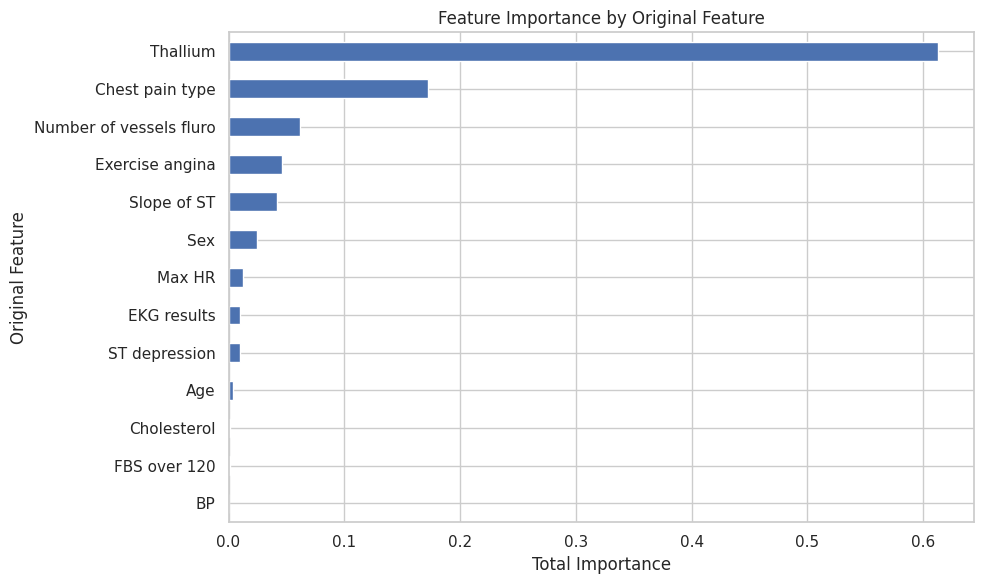

In [58]:
# ==========================================
# AGGREGATED FEATURE IMPORTANCE
# ==========================================

feature_importance['Original Feature'] = (
    feature_importance['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
    .str.replace(r'_[0-9]+\.0$', '', regex=True)
)

aggregated_importance = (
    feature_importance
    .groupby('Original Feature')['Importance']
    .sum()
    .sort_values(ascending=False)
)

print("AGGREGATED FEATURE IMPORTANCE")
print("=" * 40)

display(aggregated_importance.to_frame())

aggregated_importance.sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    title='Feature Importance by Original Feature'
)

plt.xlabel("Total Importance")
plt.tight_layout()
plt.show()

,Feature,Importance,Std
12,Thallium,0.040273,0.000367
2,Chest pain type,0.029759,0.000318
7,Max HR,0.023337,0.000347
11,Number of vessels fluro,0.014665,0.000197
8,Exercise angina,0.008797,0.000117
1,Sex,0.007304,0.000187
10,Slope of ST,0.007188,0.000133
9,ST depression,0.004322,0.000065
0,Age,0.004232,0.000099
6,EKG results,0.001481,0.000073


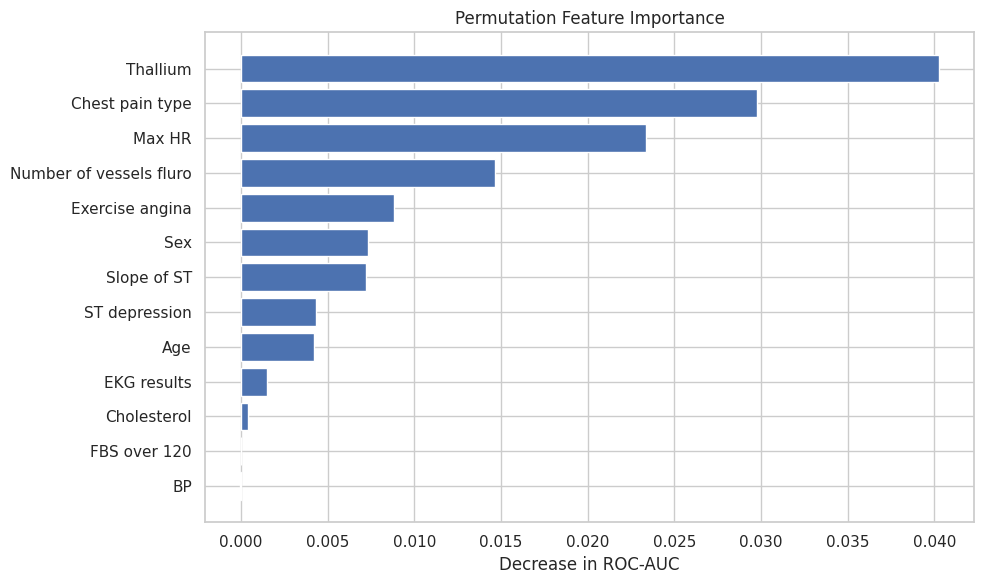

In [59]:
# ==========================================
# PERMUTATION FEATURE IMPORTANCE
# ==========================================

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    xgb_model,
    X_val,
    y_val,
    scoring='roc_auc',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

display(permutation_df)

plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df['Feature'][::-1],
    permutation_df['Importance'][::-1]
)

plt.xlabel("Decrease in ROC-AUC")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

# Experiment 5 — Linear SVM

In [60]:
# ==========================================
# EXPERIMENT 5 - LINEAR SVM
# ==========================================

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
import time

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

start_time = time.perf_counter()

svm_model.fit(X_train, y_train)

svm_training_time = time.perf_counter() - start_time

print("LINEAR SVM TRAINING COMPLETED!")
print(f"Training time: {svm_training_time:.2f} seconds")

LINEAR SVM TRAINING COMPLETED!
Training time: 2.35 seconds


In [61]:
# ==========================================
# LINEAR SVM - MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

svm_pred = svm_model.predict(X_val)

# Linear SVM provides decision scores, not probabilities
svm_scores = svm_model.decision_function(X_val)

print("LINEAR SVM RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, svm_pred))
print("Precision:", precision_score(y_val, svm_pred))
print("Recall:", recall_score(y_val, svm_pred))
print("F1 Score:", f1_score(y_val, svm_pred))
print("ROC-AUC:", roc_auc_score(y_val, svm_scores))

print("\nClassification Report:")
print(classification_report(y_val, svm_pred))

LINEAR SVM RESULTS
Accuracy: 0.8868650793650794
Precision: 0.8844809379892947
Recall: 0.8599776955621249
F1 Score: 0.8720572264555678
ROC-AUC: 0.9536866038279144

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90     69509
           1       0.88      0.86      0.87     56491

    accuracy                           0.89    126000
   macro avg       0.89      0.88      0.89    126000
weighted avg       0.89      0.89      0.89    126000



In [62]:
!pip install -q lightgbm

from lightgbm import LGBMClassifier
import time

# ==========================================
# EXPERIMENT 6 - LIGHTGBM
# ==========================================

lgbm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

start_time = time.perf_counter()

lgbm_model.fit(X_train, y_train)

lgbm_training_time = time.perf_counter() - start_time

print("LIGHTGBM TRAINING COMPLETED!")
print(f"Training time: {lgbm_training_time:.2f} seconds")

LIGHTGBM TRAINING COMPLETED!
Training time: 7.32 seconds


In [63]:
# ==========================================
# LIGHTGBM - MODEL EVALUATION
# ==========================================

lgbm_pred = lgbm_model.predict(X_val)
lgbm_prob = lgbm_model.predict_proba(X_val)[:, 1]

print("LIGHTGBM RESULTS")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, lgbm_pred))
print("Precision:", precision_score(y_val, lgbm_pred))
print("Recall:", recall_score(y_val, lgbm_pred))
print("F1 Score:", f1_score(y_val, lgbm_pred))
print("ROC-AUC:", roc_auc_score(y_val, lgbm_prob))

print("\nClassification Report:")
print(classification_report(y_val, lgbm_pred))

LIGHTGBM RESULTS
Accuracy: 0.8894920634920634
Precision: 0.8829413987297361
Recall: 0.8686870474942912
F1 Score: 0.8757562237887034
ROC-AUC: 0.9558151766210464

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90     69509
           1       0.88      0.87      0.88     56491

    accuracy                           0.89    126000
   macro avg       0.89      0.89      0.89    126000
weighted avg       0.89      0.89      0.89    126000



In [64]:
# ==========================================
# FINAL COMPARISON - ALL FIVE ALGORITHMS
# ==========================================

final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost',
        'Linear SVM',
        'LightGBM'
    ],

    'Accuracy': [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, xgb_pred),
        accuracy_score(y_val, svm_pred),
        accuracy_score(y_val, lgbm_pred)
    ],

    'Precision': [
        precision_score(y_val, y_pred),
        precision_score(y_val, rf_pred),
        precision_score(y_val, xgb_pred),
        precision_score(y_val, svm_pred),
        precision_score(y_val, lgbm_pred)
    ],

    'Recall': [
        recall_score(y_val, y_pred),
        recall_score(y_val, rf_pred),
        recall_score(y_val, xgb_pred),
        recall_score(y_val, svm_pred),
        recall_score(y_val, lgbm_pred)
    ],

    'F1 Score': [
        f1_score(y_val, y_pred),
        f1_score(y_val, rf_pred),
        f1_score(y_val, xgb_pred),
        f1_score(y_val, svm_pred),
        f1_score(y_val, lgbm_pred)
    ],

    'ROC-AUC': [
        roc_auc_score(y_val, y_prob),
        roc_auc_score(y_val, rf_prob),
        roc_auc_score(y_val, xgb_prob),
        roc_auc_score(y_val, svm_scores),
        roc_auc_score(y_val, lgbm_prob)
    ]
})

display(
    final_results.sort_values(
        by='ROC-AUC',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.8895,0.8834,0.8680,0.8757,0.9559
4,LightGBM,0.8895,0.8829,0.8687,0.8758,0.9558
0,Logistic Regression,0.8871,0.8838,0.8613,0.8724,0.9537
3,Linear SVM,0.8869,0.8845,0.8600,0.8721,0.9537
1,Random Forest,0.8847,0.8766,0.8645,0.8705,0.9507


In [65]:
# ==========================================
# STRATIFIED 5-FOLD CROSS VALIDATION
# ==========================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    'Logistic Regression': logistic_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'Linear SVM': svm_model,
    'LightGBM': lgbm_model
}

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_results = []

for name, model in models.items():

    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

display(
    cv_comparison.sort_values(
        by='ROC-AUC',
        ascending=False
    ).round(4)
)


Evaluating Logistic Regression...
Evaluating Random Forest...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:    8.9s
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:   39.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:   40.5s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    1.7s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    1.8s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    1.8s
[Parallel(n_jobs=4)]: Done 200 out of 200 | elapsed:    1.9s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:   10.7s
[Parallel(n_jobs=-1)]: Done 192 tasks

Evaluating XGBoost...
Evaluating Linear SVM...
Evaluating LightGBM...


,Model,Accuracy,Accuracy Std,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.8878,0.0006,0.8814,0.8664,0.8738,0.9548
4,LightGBM,0.8880,0.0008,0.8816,0.8665,0.8740,0.9548
0,Logistic Regression,0.8851,0.0005,0.8812,0.8596,0.8703,0.9527
3,Linear SVM,0.8851,0.0005,0.8821,0.8586,0.8702,0.9527
1,Random Forest,0.8831,0.0007,0.8748,0.8628,0.8688,0.9498


In [66]:
# Check duplicate feature combinations

X_check = playground_clean.drop(columns=['Heart Disease'])

duplicate_count = X_check.duplicated().sum()

print("Total records:", len(X_check))
print("Duplicate feature combinations:", duplicate_count)
print("Unique feature combinations:", X_check.drop_duplicates().shape[0])
print("Duplicate percentage:", round(duplicate_count / len(X_check) * 100, 4), "%")

Total records: 630000
Duplicate feature combinations: 0
Unique feature combinations: 630000
Duplicate percentage: 0.0 %


In [67]:
# Check whether identical feature combinations have different target labels

duplicate_groups = (
    playground_clean
    .groupby(X_check.columns.tolist())['Heart Disease']
    .nunique()
)

print("Feature groups with conflicting labels:",
      (duplicate_groups > 1).sum())

Feature groups with conflicting labels: 0


In [68]:
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np

# Predictions on the same validation dataset
xgb_pred = xgb_model.predict(X_val)
lgbm_pred = lgbm_model.predict(X_val)

xgb_prob = xgb_model.predict_proba(X_val)[:, 1]
lgbm_prob = lgbm_model.predict_proba(X_val)[:, 1]

# Compare predictions
disagreement = np.mean(xgb_pred != lgbm_pred)

print("XGBoost Accuracy:", accuracy_score(y_val, xgb_pred))
print("LightGBM Accuracy:", accuracy_score(y_val, lgbm_pred))

print("\nXGBoost ROC-AUC:", roc_auc_score(y_val, xgb_prob))
print("LightGBM ROC-AUC:", roc_auc_score(y_val, lgbm_prob))

print("\nPrediction disagreement:", round(disagreement * 100, 4), "%")
print("Different predictions:", np.sum(xgb_pred != lgbm_pred))

XGBoost Accuracy: 0.8894761904761905
LightGBM Accuracy: 0.8894920634920634

XGBoost ROC-AUC: 0.9558797306563303
LightGBM ROC-AUC: 0.9558151766210464

Prediction disagreement: 0.5429 %
Different predictions: 684


In [69]:
from sklearn.metrics import confusion_matrix
from statsmodels.stats.contingency_tables import mcnemar

# Identify correct and incorrect predictions
xgb_correct = (xgb_pred == y_val)
lgbm_correct = (lgbm_pred == y_val)

# Build paired disagreement table
both_correct = np.sum(xgb_correct & lgbm_correct)
xgb_only_correct = np.sum(xgb_correct & ~lgbm_correct)
lgbm_only_correct = np.sum(~xgb_correct & lgbm_correct)
both_wrong = np.sum(~xgb_correct & ~lgbm_correct)

table = [
    [both_correct, xgb_only_correct],
    [lgbm_only_correct, both_wrong]
]

print("Paired Prediction Table:")
print(np.array(table))

# McNemar's test
result = mcnemar(table, exact=False, correction=True)

print("\nMcNemar Test Statistic:", result.statistic)
print("P-value:", result.pvalue)

if result.pvalue < 0.05:
    print("The difference is statistically significant.")
else:
    print("No statistically significant difference detected.")

Paired Prediction Table:
[[111733    341]
 [   343  13583]]

McNemar Test Statistic: 0.0014619883040935672
P-value: 0.969499553386959
No statistically significant difference detected.


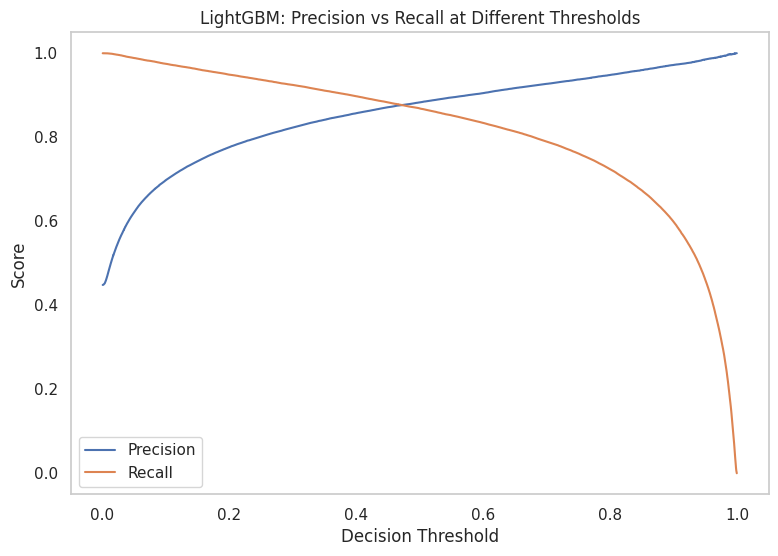

In [70]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_val, lgbm_prob
)

plt.figure(figsize=(9, 6))
plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('LightGBM: Precision vs Recall at Different Thresholds')
plt.legend()
plt.grid()
plt.show()

In [71]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (lgbm_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1 Score': f1_score(y_val, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score
0,0.30,0.8232,0.9245,0.8709
1,0.35,0.8416,0.9110,0.8749
2,0.40,0.8572,0.8977,0.8770
3,0.45,0.8715,0.8829,0.8772
4,0.50,0.8829,0.8687,0.8758
5,0.55,0.8947,0.8523,0.8730
6,0.60,0.9051,0.8342,0.8682


In [72]:
from sklearn.metrics import confusion_matrix, classification_report

chosen_threshold = 0.40

lgbm_tuned_pred = (lgbm_prob >= chosen_threshold).astype(int)

cm = confusion_matrix(y_val, lgbm_tuned_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_val,
    lgbm_tuned_pred,
    target_names=['Absence', 'Presence']
))

Confusion Matrix:
[[61060  8449]
 [ 5781 50710]]

Classification Report:
              precision    recall  f1-score   support

     Absence       0.91      0.88      0.90     69509
    Presence       0.86      0.90      0.88     56491

    accuracy                           0.89    126000
   macro avg       0.89      0.89      0.89    126000
weighted avg       0.89      0.89      0.89    126000



LightGBM Brier Score: 0.08079


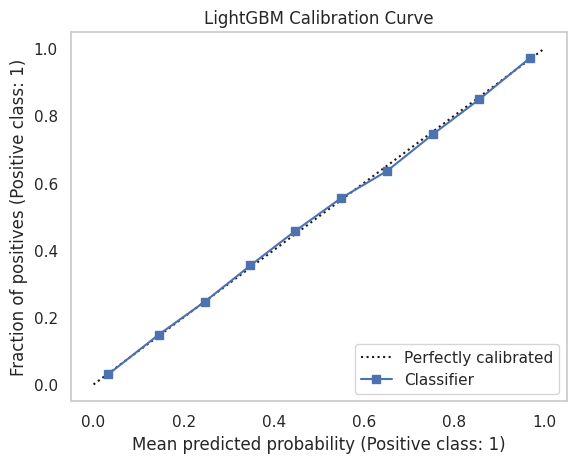

In [73]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

brier = brier_score_loss(y_val, lgbm_prob)

print("LightGBM Brier Score:", round(brier, 5))

CalibrationDisplay.from_predictions(
    y_val,
    lgbm_prob,
    n_bins=10,
    strategy='uniform'
)

plt.title("LightGBM Calibration Curve")
plt.grid()
plt.show()

In [74]:
!pip install -q shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [75]:
# Sample validation records for SHAP analysis

X_shap = X_val.sample(
    n=1000,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (1000, 13)


In [76]:
# Access the trained LightGBM classifier
lgbm_classifier = lgbm_model.named_steps['classifier']

# Apply preprocessing to the SHAP sample
X_shap_transformed = lgbm_model.named_steps['preprocessor'].transform(X_shap)

# Get transformed feature names
feature_names = lgbm_model.named_steps['preprocessor'].get_feature_names_out()

# Convert to DataFrame
X_shap_transformed = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names
)

# Create SHAP explainer
explainer = shap.TreeExplainer(lgbm_classifier)

# Calculate SHAP values
shap_values = explainer(X_shap_transformed)

print("SHAP calculation completed!")
print("SHAP values shape:", shap_values.values.shape)

SHAP calculation completed!
SHAP values shape: (1000, 28)


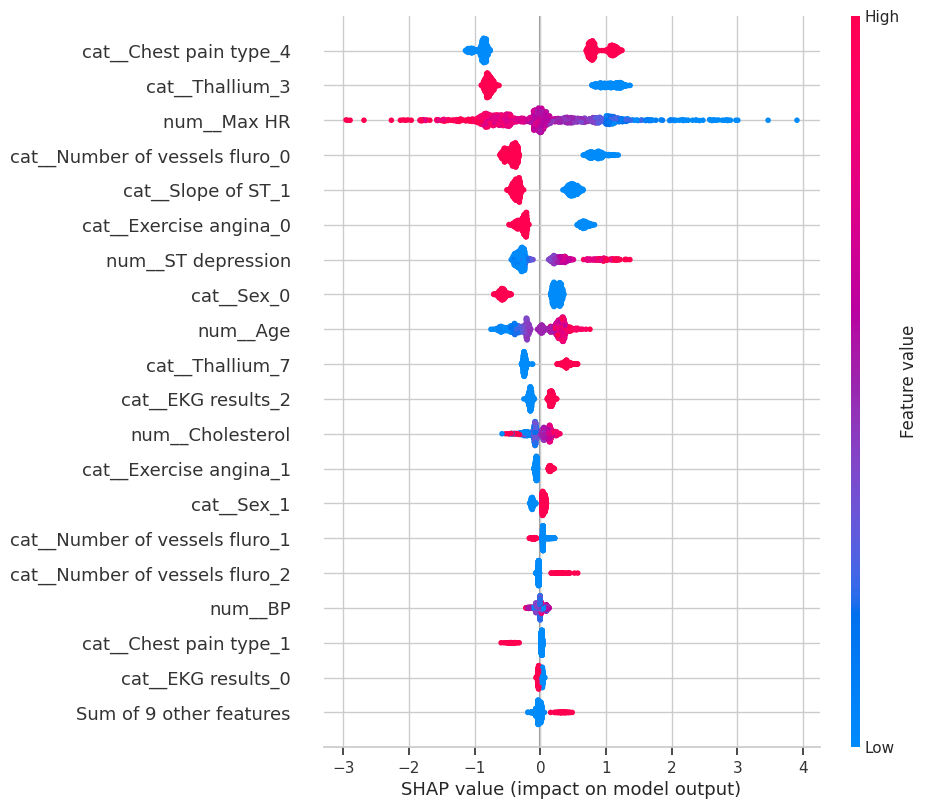

In [77]:
shap.plots.beeswarm(shap_values, max_display=20)

In [78]:
# Calculate mean absolute SHAP importance
shap_importance = np.abs(shap_values.values).mean(axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': shap_importance
})

# Group encoded features by their original feature name
importance_df['Original Feature'] = (
    importance_df['Feature']
    .str.replace(r'^(num|cat)__', '', regex=True)
    .str.replace(r'_[^_]+$', '', regex=True)
)

# Aggregate importance
grouped_importance = (
    importance_df
    .groupby('Original Feature')['SHAP Importance']
    .sum()
    .sort_values(ascending=False)
)

display(grouped_importance.to_frame().round(5))

,SHAP Importance
Original Feature,
Thallium,1.19808
Chest pain type,0.95884
Number of vessels fluro,0.69684
Max HR,0.67120
Exercise angina,0.47393
Slope of ST,0.44356
Sex,0.41523
ST depression,0.36148
Age,0.31306


In [79]:
# Prepare original UCI features and target

X_uci_test = X_uci.copy()
y_uci_test = y_uci.copy()

print("UCI feature shape:", X_uci_test.shape)
print("UCI target shape:", y_uci_test.shape)

print("\nTarget distribution:")
print(y_uci_test.value_counts())

UCI feature shape: (303, 13)
UCI target shape: (303,)

Target distribution:
Heart Disease
0    164
1    139
Name: count, dtype: int64


In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict on original UCI dataset
uci_pred = lgbm_model.predict(X_uci_test)
uci_prob = lgbm_model.predict_proba(X_uci_test)[:, 1]

# Evaluation metrics
print("LightGBM: Playground-trained → UCI dataset")
print("--------------------------------------------")
print("Accuracy:", round(accuracy_score(y_uci_test, uci_pred), 4))
print("Precision:", round(precision_score(y_uci_test, uci_pred), 4))
print("Recall:", round(recall_score(y_uci_test, uci_pred), 4))
print("F1 Score:", round(f1_score(y_uci_test, uci_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_uci_test, uci_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_uci_test, uci_pred))

print("\nClassification Report:")
print(classification_report(
    y_uci_test,
    uci_pred,
    target_names=["Absence", "Presence"]
))

LightGBM: Playground-trained → UCI dataset
--------------------------------------------
Accuracy: 0.8218
Precision: 0.7972
Recall: 0.8201
F1 Score: 0.8085
ROC-AUC: 0.9182

Confusion Matrix:
[[135  29]
 [ 25 114]]

Classification Report:
              precision    recall  f1-score   support

     Absence       0.84      0.82      0.83       164
    Presence       0.80      0.82      0.81       139

    accuracy                           0.82       303
   macro avg       0.82      0.82      0.82       303
weighted avg       0.82      0.82      0.82       303



In [81]:
# Playground-trained XGBoost → Original UCI

xgb_uci_pred = xgb_model.predict(X_uci_test)
xgb_uci_prob = xgb_model.predict_proba(X_uci_test)[:, 1]

print("XGBoost: Playground-trained → UCI")
print("----------------------------------")

print("Accuracy:", round(accuracy_score(y_uci_test, xgb_uci_pred), 4))
print("Precision:", round(precision_score(y_uci_test, xgb_uci_pred), 4))
print("Recall:", round(recall_score(y_uci_test, xgb_uci_pred), 4))
print("F1 Score:", round(f1_score(y_uci_test, xgb_uci_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_uci_test, xgb_uci_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_uci_test, xgb_uci_pred))

XGBoost: Playground-trained → UCI
----------------------------------
Accuracy: 0.8185
Precision: 0.7917
Recall: 0.8201
F1 Score: 0.8057
ROC-AUC: 0.9173

Confusion Matrix:
[[134  30]
 [ 25 114]]


In [82]:
# ==========================================
# EXPERIMENT 4: LIGHTGBM ON UCI DATASET
# ==========================================

lgbm_uci_model = Pipeline(steps=[
    ('preprocessor', preprocessor),

    ('classifier', LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

print("UCI LightGBM pipeline created!")

UCI LightGBM pipeline created!


In [83]:
# ==========================================
# LIGHTGBM TRAINING ON UCI DATASET
# ==========================================

start_time = time.perf_counter()

lgbm_uci_model.fit(X_uci_train, y_uci_train)

end_time = time.perf_counter()

lgbm_uci_training_time = end_time - start_time

print("UCI LightGBM training completed!")
print(f"Training time: {lgbm_uci_training_time:.2f} seconds")
print(f"Training time: {lgbm_uci_training_time/60:.2f} minutes")

UCI LightGBM training completed!
Training time: 0.10 seconds
Training time: 0.00 minutes


In [84]:
# ==========================================
# LIGHTGBM UCI MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

y_uci_pred = lgbm_uci_model.predict(X_uci_test)
y_uci_prob = lgbm_uci_model.predict_proba(X_uci_test)[:, 1]

print("LIGHTGBM — UCI TEST RESULTS")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_uci_test, y_uci_pred):.4f}")
print(f"Precision: {precision_score(y_uci_test, y_uci_pred):.4f}")
print(f"Recall:    {recall_score(y_uci_test, y_uci_pred):.4f}")
print(f"F1 Score:  {f1_score(y_uci_test, y_uci_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_uci_test, y_uci_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_uci_test, y_uci_pred))

print("\nClassification Report:")
print(classification_report(y_uci_test, y_uci_pred))

LIGHTGBM — UCI TEST RESULTS
--------------------------------
Accuracy:  0.9868
Precision: 0.9787
Recall:    0.9928
F1 Score:  0.9857
ROC-AUC:   0.9945

Confusion Matrix:
[[161   3]
 [  1 138]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       164
           1       0.98      0.99      0.99       139

    accuracy                           0.99       303
   macro avg       0.99      0.99      0.99       303
weighted avg       0.99      0.99      0.99       303



In [86]:
print("UCI training records:", len(X_uci_train))
print("UCI testing records:", len(X_uci_test))
print("Predictions:", len(y_uci_pred))
print("Actual test labels:", len(y_uci_test))

UCI training records: 242
UCI testing records: 303
Predictions: 303
Actual test labels: 303


In [87]:
# ==========================================
# RESTORE UCI TRAIN-TEST SPLIT
# ==========================================

X_uci_train, X_uci_test, y_uci_train, y_uci_test = train_test_split(
    X_uci,
    y_uci,
    test_size=0.20,
    random_state=42,
    stratify=y_uci
)

print("Training:", X_uci_train.shape)
print("Testing:", X_uci_test.shape)

Training: (242, 13)
Testing: (61, 13)


In [88]:
# ==========================================
# LIGHTGBM TRAINING ON UCI DATASET
# ==========================================

start_time = time.perf_counter()

lgbm_uci_model.fit(X_uci_train, y_uci_train)

end_time = time.perf_counter()

lgbm_uci_training_time = end_time - start_time

print("UCI LightGBM training completed!")
print(f"Training time: {lgbm_uci_training_time:.2f} seconds")
print(f"Training time: {lgbm_uci_training_time / 60:.2f} minutes")

UCI LightGBM training completed!
Training time: 0.09 seconds
Training time: 0.00 minutes


In [89]:
# ==========================================
# LIGHTGBM UCI MODEL EVALUATION
# ==========================================

y_uci_pred = lgbm_uci_model.predict(X_uci_test)
y_uci_prob = lgbm_uci_model.predict_proba(X_uci_test)[:, 1]

print("LIGHTGBM — UCI TEST RESULTS")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_uci_test, y_uci_pred):.4f}")
print(f"Precision: {precision_score(y_uci_test, y_uci_pred):.4f}")
print(f"Recall:    {recall_score(y_uci_test, y_uci_pred):.4f}")
print(f"F1 Score:  {f1_score(y_uci_test, y_uci_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_uci_test, y_uci_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_uci_test, y_uci_pred))

print("\nClassification Report:")
print(classification_report(y_uci_test, y_uci_pred))

LIGHTGBM — UCI TEST RESULTS
--------------------------------
Accuracy:  0.9344
Precision: 0.9000
Recall:    0.9643
F1 Score:  0.9310
ROC-AUC:   0.9643

Confusion Matrix:
[[30  3]
 [ 1 27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        33
           1       0.90      0.96      0.93        28

    accuracy                           0.93        61
   macro avg       0.93      0.94      0.93        61
weighted avg       0.94      0.93      0.93        61



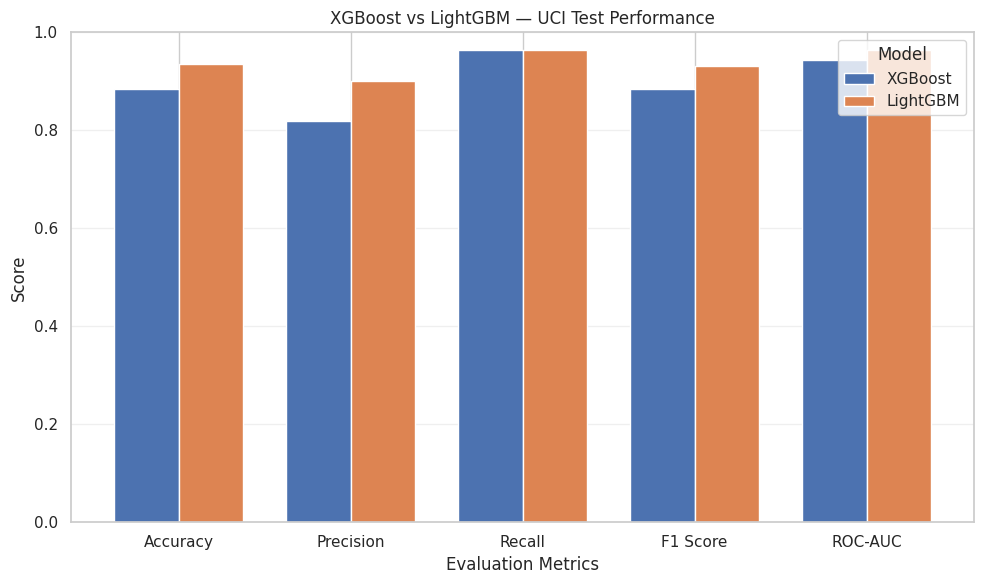

In [90]:
# ==========================================
# XGBOOST VS LIGHTGBM — UCI COMPARISON
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'XGBoost': [0.8852, 0.8182, 0.9643, 0.8852, 0.9426],
    'LightGBM': [0.9344, 0.9000, 0.9643, 0.9310, 0.9643]
})

comparison.plot(
    x='Metric',
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title('XGBoost vs LightGBM — UCI Test Performance')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [91]:
# ==========================================
# FINAL MODEL COMPARISON
# ==========================================

final_results = pd.DataFrame([
    # Playground 5-fold CV
    ['Logistic Regression', 'Playground CV', 0.8851, 0.8812, 0.8596, 0.8703, 0.9527],
    ['Random Forest', 'Playground CV', 0.8831, 0.8748, 0.8628, 0.8688, 0.9498],
    ['XGBoost', 'Playground CV', 0.8878, 0.8814, 0.8664, 0.8738, 0.9548],
    ['LightGBM', 'Playground CV', 0.8880, 0.8816, 0.8665, 0.8740, 0.9548],
    ['Linear SVM', 'Playground CV', 0.8851, 0.8821, 0.8586, 0.8702, 0.9527],

    # UCI holdout
    ['XGBoost', 'UCI Holdout', 0.8852, 0.8182, 0.9643, 0.8852, 0.9426],
    ['LightGBM', 'UCI Holdout', 0.9344, 0.9000, 0.9643, 0.9310, 0.9643],

    # Cross-dataset: Playground-trained models tested on UCI
    ['XGBoost', 'Cross-Dataset', 0.8185, 0.7917, 0.8201, 0.8057, 0.9173],
    ['LightGBM', 'Cross-Dataset', 0.8218, 0.7972, 0.8201, 0.8085, 0.9182]
], columns=[
    'Model', 'Experiment', 'Accuracy',
    'Precision', 'Recall', 'F1 Score', 'ROC-AUC'
])

display(
    final_results.style
    .format({
        'Accuracy': '{:.2%}',
        'Precision': '{:.2%}',
        'Recall': '{:.2%}',
        'F1 Score': '{:.2%}',
        'ROC-AUC': '{:.2%}'
    })
    .background_gradient(cmap='YlGn', subset=[
        'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'
    ])
)

print("Final model comparison completed!")

,Model,Experiment,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,Playground CV,88.51%,88.12%,85.96%,87.03%,95.27%
1,Random Forest,Playground CV,88.31%,87.48%,86.28%,86.88%,94.98%
2,XGBoost,Playground CV,88.78%,88.14%,86.64%,87.38%,95.48%
3,LightGBM,Playground CV,88.80%,88.16%,86.65%,87.40%,95.48%
4,Linear SVM,Playground CV,88.51%,88.21%,85.86%,87.02%,95.27%
5,XGBoost,UCI Holdout,88.52%,81.82%,96.43%,88.52%,94.26%
6,LightGBM,UCI Holdout,93.44%,90.00%,96.43%,93.10%,96.43%
7,XGBoost,Cross-Dataset,81.85%,79.17%,82.01%,80.57%,91.73%
8,LightGBM,Cross-Dataset,82.18%,79.72%,82.01%,80.85%,91.82%


Final model comparison completed!


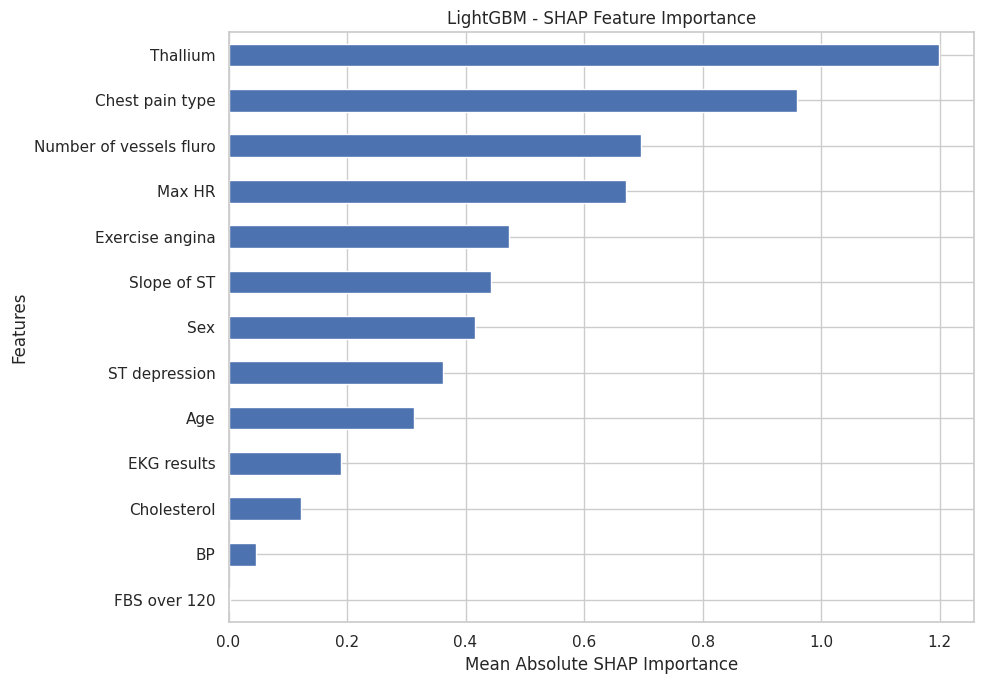

In [92]:
# ==========================================
# SHAP FEATURE IMPORTANCE
# ==========================================

plt.figure(figsize=(10, 7))

grouped_importance.sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('LightGBM - SHAP Feature Importance')
plt.xlabel('Mean Absolute SHAP Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

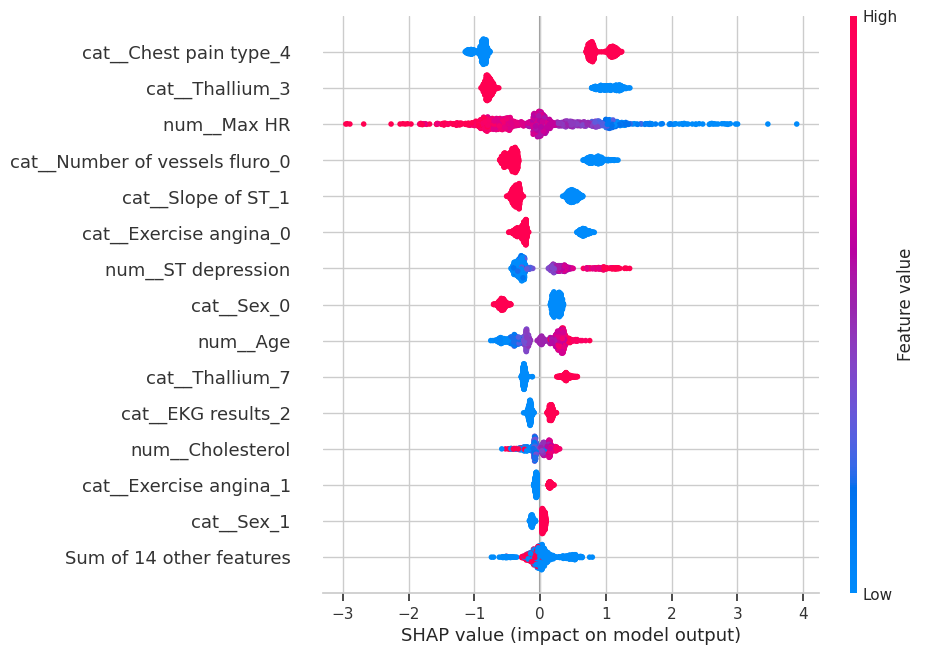

In [93]:
# ==========================================
# SHAP SUMMARY / BEESWARM PLOT
# ==========================================

shap.plots.beeswarm(shap_values, max_display=15)

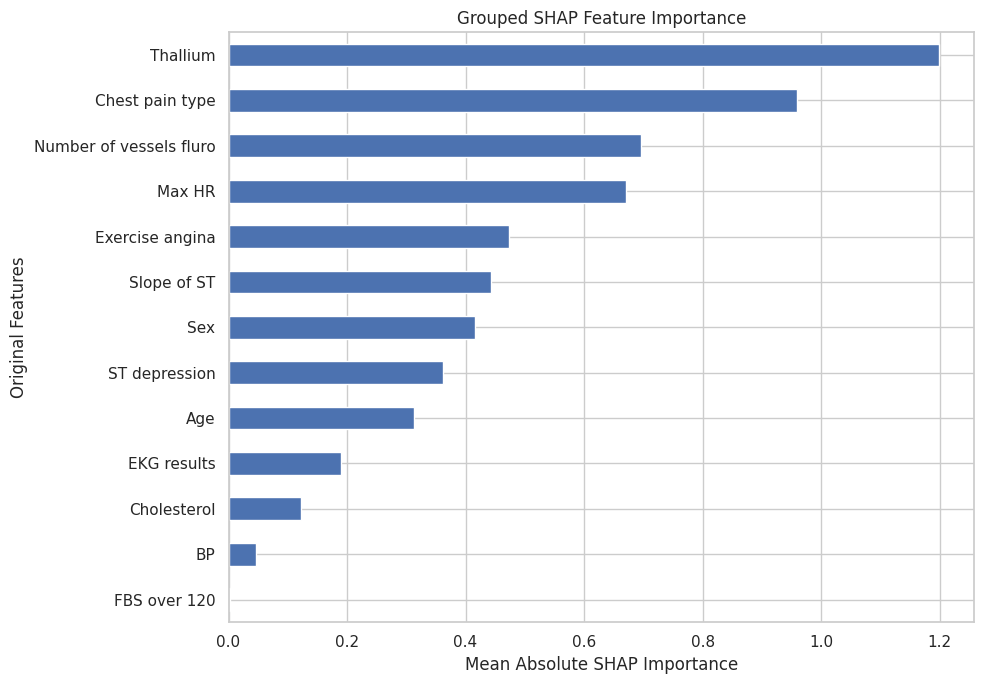

In [94]:
# ==========================================
# GROUPED SHAP FEATURE IMPORTANCE
# ==========================================

grouped_importance.sort_values().plot(
    kind='barh',
    figsize=(10, 7),
    title='Grouped SHAP Feature Importance'
)

plt.xlabel('Mean Absolute SHAP Importance')
plt.ylabel('Original Features')
plt.tight_layout()
plt.show()

In [96]:
# ==========================================
# STEP 1: SAVE TRAINED MODELS
# ==========================================

import joblib
import os

# Create output directory
os.makedirs('/kaggle/working/models', exist_ok=True)

# Save Playground-trained LightGBM
joblib.dump(
    lgbm_model,
    '/kaggle/working/models/lightgbm_playground.pkl'
)

# Save UCI-trained LightGBM
joblib.dump(
    lgbm_uci_model,
    '/kaggle/working/models/lightgbm_uci.pkl'
)

print("Models saved successfully!")

print("\nSaved files:")
print(os.listdir('/kaggle/working/models'))

Models saved successfully!

Saved files:
['lightgbm_uci.pkl', 'lightgbm_playground.pkl']


In [97]:
# ==========================================
# STEP 2: LOAD SAVED MODELS
# ==========================================

loaded_playground_model = joblib.load(
    '/kaggle/working/models/lightgbm_playground.pkl'
)

loaded_uci_model = joblib.load(
    '/kaggle/working/models/lightgbm_uci.pkl'
)

print("Both models loaded successfully!")

# Test Playground model
playground_predictions = loaded_playground_model.predict(X_val.head(5))

# Test UCI model
uci_predictions = loaded_uci_model.predict(X_uci_test.head(5))

print("\nPlayground predictions:", playground_predictions)
print("UCI predictions:", uci_predictions)


Both models loaded successfully!

Playground predictions: [0 1 1 1 1]
UCI predictions: [0 0 0 0 0]


In [99]:
# ==========================================
# STEP 3: PREDICTION PROBABILITY TEST
# ==========================================

playground_probabilities = loaded_playground_model.predict_proba(
    X_val.head(5)
)

uci_probabilities = loaded_uci_model.predict_proba(
    X_uci_test.head(5)
)

print("PLAYGROUND PREDICTION PROBABILITIES")
print(playground_probabilities)

print("\nUCI PREDICTION PROBABILITIES")
print(uci_probabilities)

print("\nProbability verification:")
print("Playground valid:",
      ((playground_probabilities >= 0) &
       (playground_probabilities <= 1)).all())

print("UCI valid:",
      ((uci_probabilities >= 0) &
       (uci_probabilities <= 1)).all())

PLAYGROUND PREDICTION PROBABILITIES
[[0.99769846 0.00230154]
 [0.00475403 0.99524597]
 [0.02047336 0.97952664]
 [0.05922712 0.94077288]
 [0.00794886 0.99205114]]

UCI PREDICTION PROBABILITIES
[[7.48475728e-01 2.51524272e-01]
 [5.15715035e-01 4.84284965e-01]
 [9.99330261e-01 6.69739033e-04]
 [9.99434758e-01 5.65241606e-04]
 [9.73272714e-01 2.67272860e-02]]

Probability verification:
Playground valid: True
UCI valid: True


# Conclusion

This project developed and evaluated machine learning models for heart disease prediction using two datasets: the original UCI Heart Disease dataset and the Kaggle Playground Series S6E2 dataset.

Five machine learning algorithms were investigated: Logistic Regression, Random Forest, XGBoost, Linear SVM, and LightGBM.

LightGBM achieved the best average accuracy in the Playground five-fold cross-validation experiment, with 88.80% accuracy and an ROC-AUC of 95.48%.

On the original UCI dataset, LightGBM achieved 93.44% accuracy, 90.00% precision, 96.43% recall, and 96.43% ROC-AUC on a 61-record holdout set.

Cross-dataset evaluation was also conducted by training models on the Playground dataset and testing them on the UCI dataset. LightGBM achieved 82.18% accuracy and 91.82% ROC-AUC.

SHAP analysis was used to interpret model predictions. Thallium, chest pain type, number of vessels fluro, and maximum heart rate were among the most influential features in the trained LightGBM model.

# Limitations

1. The original UCI dataset contains only 303 records, limiting the reliability and generalizability of evaluation results.
2. The Playground dataset is synthetic and may not fully represent real-world patient data.
3. The UCI holdout test set contains only 61 records, so its performance estimates have considerable uncertainty.
4. Model predictions are influenced by the quality and characteristics of the training datasets.
5. SHAP feature importance represents model behaviour and does not establish medical causation.
6. The models have not undergone independent clinical validation.

# Future Scope

- Evaluate models using larger and more diverse real-world datasets.
- Perform external validation using independent patient populations.
- Investigate hyperparameter optimization and additional machine learning algorithms.
- Improve probability calibration and evaluate decision thresholds.
- Develop an interactive application for research and educational demonstration.

# Final Statement

The experiments demonstrate the potential of machine learning techniques for identifying patterns associated with heart disease in structured datasets. LightGBM showed consistently strong predictive performance across the experiments. However, further validation using larger, independent clinical datasets is necessary before considering any real-world medical application.

In [100]:
# ==========================================
# STEP 5: ORGANIZE PROJECT OUTPUT
# ==========================================

import os
import shutil

project_dir = '/kaggle/working/heart-disease-project'

os.makedirs(project_dir, exist_ok=True)
os.makedirs(f'{project_dir}/models', exist_ok=True)
os.makedirs(f'{project_dir}/results', exist_ok=True)

# Copy trained models
shutil.copy(
    '/kaggle/working/models/lightgbm_playground.pkl',
    f'{project_dir}/models/'
)

shutil.copy(
    '/kaggle/working/models/lightgbm_uci.pkl',
    f'{project_dir}/models/'
)

# Save final comparison table
final_results.to_csv(
    f'{project_dir}/results/model_comparison.csv',
    index=False
)

print("Project files organized successfully!")

for root, dirs, files in os.walk(project_dir):
    print(root, files)

Project files organized successfully!
/kaggle/working/heart-disease-project []
/kaggle/working/heart-disease-project/models ['lightgbm_uci.pkl', 'lightgbm_playground.pkl']
/kaggle/working/heart-disease-project/results ['model_comparison.csv']


In [101]:
# ==========================================
# STEP 7: CAPTURE LIBRARY VERSIONS
# ==========================================

import sklearn
import pandas
import numpy
import xgboost
import lightgbm
import shap
import joblib

packages = {
    'scikit-learn': sklearn.__version__,
    'pandas': pandas.__version__,
    'numpy': numpy.__version__,
    'xgboost': xgboost.__version__,
    'lightgbm': lightgbm.__version__,
    'shap': shap.__version__,
    'joblib': joblib.__version__
}

with open('/kaggle/working/requirements.txt', 'w') as f:
    for package, version in packages.items():
        f.write(f'{package}=={version}\n')

print("Requirements file created!")
print("\n".join(
    f"{package}=={version}"
    for package, version in packages.items()
))

Requirements file created!
scikit-learn==1.6.1
pandas==2.3.3
numpy==2.1.3
xgboost==3.4.1
lightgbm==4.6.0
shap==0.54.1
joblib==1.6.0


In [102]:
# ==========================================
# STEP 8: ADD REQUIREMENTS TO PROJECT
# ==========================================

import shutil
import os

shutil.copy(
    '/kaggle/working/requirements.txt',
    '/kaggle/working/heart-disease-project/requirements.txt'
)

print("Requirements added successfully!")

print("\nProject files:")
for root, dirs, files in os.walk('/kaggle/working/heart-disease-project'):
    for file in files:
        print(os.path.join(root, file))

Requirements added successfully!

Project files:
/kaggle/working/heart-disease-project/requirements.txt
/kaggle/working/heart-disease-project/models/lightgbm_uci.pkl
/kaggle/working/heart-disease-project/models/lightgbm_playground.pkl
/kaggle/working/heart-disease-project/results/model_comparison.csv


In [103]:
# ==========================================
# STEP 9: CREATE PROJECT README
# ==========================================

readme_content = """
# Heart Disease Prediction Using Machine Learning

## Overview
A machine learning project exploring heart disease prediction
using the UCI Heart Disease dataset and Kaggle Playground
Series S6E2 dataset.

## Objectives
- Perform exploratory data analysis.
- Preprocess structured health-related data.
- Compare multiple machine learning algorithms.
- Evaluate cross-dataset generalization.
- Interpret predictions using SHAP.

## Datasets
1. UCI Heart Disease Dataset (303 records).
2. Kaggle Playground Series S6E2 (630,000 training records).

## Algorithms
- Logistic Regression
- Random Forest
- XGBoost
- Linear SVM
- LightGBM

## Best Results

### Playground 5-Fold Cross-Validation
- LightGBM Accuracy: 88.80%
- LightGBM ROC-AUC: 95.48%

### UCI Holdout Evaluation
- LightGBM Accuracy: 93.44%
- LightGBM ROC-AUC: 96.43%

### Cross-Dataset Evaluation
- LightGBM Accuracy: 82.18%
- LightGBM ROC-AUC: 91.82%

## Explainability
SHAP analysis identified Thallium, Chest pain type,
Number of vessels fluro, and Max HR among the most
influential features in the trained LightGBM model.

## Technologies
Python, Pandas, NumPy, Scikit-learn, XGBoost,
LightGBM, SHAP, Matplotlib and Joblib.

## Project Structure
- models/: Saved LightGBM pipelines.
- results/: Model comparison results.
- requirements.txt: Kaggle library versions.

## Limitations
- UCI dataset contains only 303 records.
- Playground dataset is synthetic.
- UCI holdout evaluation contains only 61 records.
- External clinical validation has not been performed.

## Disclaimer
This project is for educational and research purposes only.
It is not a medical diagnostic tool.
"""

readme_path = '/kaggle/working/heart-disease-project/README.md'

with open(readme_path, 'w', encoding='utf-8') as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Location:", readme_path)

README.md created successfully!
Location: /kaggle/working/heart-disease-project/README.md
